# CACIB calibration: S&P 500 and EURO STOXX 50

This notebook calibrates the one-asset Volterra Stein–Stein model to the CACIB
consensus market data for **31 January 2025** and **31 July 2025**. Each
index–valuation-date pair is a separate calibration: `SPX_20250131`,
`SPX_20250731`, `SX5E_20250131`, or `SX5E_20250731`.

It reads the four standardized workbooks in `Market datas/CACIB/processed`,
calibrates a piecewise-constant $G_0$ exactly to each variance-swap term
structure, and then calibrates the fractional, shifted-fractional,
one-exponential and two-exponential kernels to ATM skew. S&P 500 also has
volatility swaps, which are calibrated separately for each kernel. EURO
STOXX 50 has no volatility-swap quotes, so no such calibration is attempted.
The notebook ends by comparing the four kernels.

The implied-volatility workbooks already contain the interpolated consensus
volatilities at **forward** log-moneyness $k_- = \log(0.99)$ and
$k_+ = \log(1.01)$. The market skew is their direct two-point slope, without
another interpolation. The model uses the same two points. All maturities
present in the four workbooks are retained, with no additional exclusion.
The 31 July implied-volatility workbooks already omit the earliest raw expiry
as documented in `prepare_iv_vars_vols_cvc_inputs.ipynb`; it is not reintroduced here.
Maturities use the provisional ACT/365F convention of the prepared files.

The numerical model and optimization structure follow
`vss_calibration_HSBC_SP500_NKY.ipynb`, including fixed $Y_0=1$, logarithmic
absolute-skew residuals, the Fourier resolution rules, and the original
kernel-specific parameter bounds. All figures are written under
`Plots vss_calibration_CACIB_SP500_SX5E`.

# Model

Let $n,d\in\mathbb{N}^*$. The volatility factor $Y\in\mathbb{R}^n$ satisfies

$$
Y_t=Y_0+\int_0^t\kappa K(t,s)Y_s\,ds+\int_0^t\nu K(t,s)\,dW_s,
$$

where $K$ is a Volterra kernel in $\mathbb{R}^{d\times n}$ and
$\kappa,\nu\in\mathbb{R}^{n\times d}$ are deterministic. This notebook takes $\kappa=0$;
the parameter called `eta` in the code corresponds to $\nu$. The asset prices follow

$$
dS_t=\operatorname{diag}(S_t)\sigma(t,Y_t)\,dB_t,
\qquad d\langle B\rangle_t=\rho\,dt,
$$

where $\rho$ is a correlation matrix. The volatility driver is

$$
W_t=C^\top B_t+\sqrt{I_n-\operatorname{diag}(C^\top C)}\,B_t^\perp,
\qquad
R_W=C^\top\rho C+I_n-\operatorname{diag}(C^\top C),
$$

with $B^\perp$ an independent $n$-dimensional standard Brownian motion,
$C\in\mathbb{R}^{d\times n}$ having columns of norm at most one, and
$d\langle W\rangle_t=R_W\,dt$. The quadratic volatility specification is

$$
\sigma(t,Y_t)=G_0(t)\big(\mathbb{E}[Z_t\rho Z_t^\top]\big)^{-1/2}Z_t,
\qquad Z_t^{ij}=\gamma_{ij}^\top Y_t,
$$

where $G_0:[0,T]\to\mathbb{R}^{d\times d}$ is deterministic and
$\mathbb{E}[Z_t\rho Z_t^\top]$ is positive definite. The normalization matches the
covariance-swap term structure:

$$
\mathbb{E}\!\left[\int_0^T\sigma(s,Y_s)\rho\sigma(s,Y_s)^\top\,ds\right]
=\int_0^T G_0(s)G_0(s)^\top\,ds.
$$

Every calibration below is one-dimensional: $n=d=1$, $Y_0=1$,
$\gamma_{11}=1$, $\rho=R_W=[1]$, and $C=[c]$ with $c\in[-1,1]$. Thus

$$
W_t=cB_t+\sqrt{1-c^2}\,B_t^\perp,
\qquad
Y_t=1+\eta\int_0^t K(t,s)\,dW_s,
\qquad
\sigma(t,Y_t)=G_0(t)\frac{Y_t}{\sqrt{\mathbb{E}[Y_t^2]}}.
$$

Here $c$ controls the leverage effect and the vol of vol is named $\eta$ in this notebook instead of $\nu$.

## Volterra kernels used in the notebook

The four kernel shapes used below are:

- Fractional kernel: $K_{\mathrm{frac}}(t,s)=\mathbf{1}_{s<t}\dfrac{(t-s)^{H-1/2}}{\Gamma(H+1/2)}$.
- Shifted fractional kernel: $K_{\mathrm{shifted}}(t,s)=\mathbf{1}_{s<t}\dfrac{(t-s+\delta)^{H-1/2}}{\Gamma(H+1/2)}$, with $\delta=5/252$.
- One-exponential kernel: $K_{\mathrm{1-exp}}(t,s)=\mathbf{1}_{s<t}\dfrac{\delta^{H-1/2}}{\Gamma(H+1/2)}\exp\left(-\dfrac{1/2-H}{\delta}(t-s)\right)$. Defining $\kappa=(1/2-H)/\delta$, this is $K_{\mathrm{1-exp}}(t,s)=\mathbf{1}_{s<t}\dfrac{\delta^{-\kappa\delta}}{\Gamma(1-\kappa\delta)}\exp(-\kappa(t-s))$.
- Two-exponential kernel: $K_{\mathrm{2-exp}}(t,s)=\mathbf{1}_{s<t}[a_1\exp(-\kappa_1(t-s))+a_2\exp(-\kappa_2(t-s))]$, with $a_2=1-a_1$.

For the one-exponential kernel, $H$ is the calibrated shape parameter and $\delta$ is fixed.

# Data extraction

The four CACIB workbooks have the prescribed product sheets and preserve the prepared forward-moneyness convention. The SX5E workbooks have no `volatility_swaps` sheet.

In [28]:
from functools import lru_cache
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
sns.set_style("darkgrid")
import numpy as np
from IPython.display import display
from scipy.optimize import least_squares
from scipy.special import gamma, roots_laguerre

PROJECT_ROOT = next((root for root in [Path.cwd(), *Path.cwd().parents]
                     if (root / 'src' / 'vss').is_dir()
                     and (root / 'Market datas' / 'CACIB' / 'processed').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the project directory or one of its descendants.')
SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

PLOTS_DIRECTORY = PROJECT_ROOT / 'Plots vss_calibration_CACIB_SP500_SX5E_skew_vars_vols_2y'
ATM_SKEW_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'atm skew'
VARIANCE_SWAP_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'variance swap'
MARKET_QUOTES_PLOTS_DIRECTORY = PLOTS_DIRECTORY / 'Market quotes'
for directory in (
    ATM_SKEW_PLOTS_DIRECTORY,
    VARIANCE_SWAP_PLOTS_DIRECTORY,
    MARKET_QUOTES_PLOTS_DIRECTORY,
):
    directory.mkdir(parents=True, exist_ok=True)

from vss.calibration.variance_swap_g0 import (
    compute_piecewise_constant_g0_from_variance_swaps,
    evaluate_piecewise_constant_g0_on_grid,
    integrated_piecewise_constant_g0_squared,
)
from vss.fourier.flt_prefactor_free import (
    matrix_sqrt_psd,
    vss_fourier_laplace_det_prefactor_free,
)
from vss.fourier.parameters import (
    compute_V_matrix_for_fourier,
    compute_tilde_g_N0,
)
from vss.fourier.skew import skew_fourier
from vss.fourier.vol_swap import vol_swap_price_fourier
from vss.kernels.one_asset.shifted_fractional import shifted_fractional_KK_SIG_d1_n1
from vss.market_data.excel_extraction import extract_market_data_from_excel
from vss.market_data.variance_swap_processing import clean_variance_swap_data
from vss.parameters import compute_M_matrix


@lru_cache(maxsize=None)
def get_laguerre_rule(Q_laguerre):
    """Return and cache the Gauss-Laguerre quadrature rule."""

    return roots_laguerre(int(Q_laguerre))

The two valuation dates are kept separate throughout the analysis. Each
workbook is read through `extract_market_data_from_excel`; missing product
sheets are represented by absence, not by synthetic observations. The
complete input tables are displayed so their coverage can be checked.

In [29]:
MARKET_DATA_DIR = PROJECT_ROOT / 'Market datas' / 'CACIB' / 'processed'

MAX_MARGINAL_MATURITY_YEARS = 2.0
DATES = ('20250131', '20250731')
DATASETS_BY_ASSET = {
    'SPX': [f'SPX_{date}' for date in DATES],
    'SX5E': [f'SX5E_{date}' for date in DATES],
}
EXCEL_FILES = {
    f'SPX_{date}': MARKET_DATA_DIR / f'CACIB_SP500_iv_vars_vols_{date}.xlsx'
    for date in DATES
}
EXCEL_FILES.update({
    f'SX5E_{date}': MARKET_DATA_DIR / f'CACIB_SX5E_iv_vars_{date}.xlsx'
    for date in DATES
})
market_data = {}
for dataset, excel_file in EXCEL_FILES.items():
    market_data[dataset] = extract_market_data_from_excel(excel_file)
    expected = {'implied_volatility', 'variance_swaps'}
    if dataset.startswith('SPX'):
        expected.add('volatility_swaps')
    if set(market_data[dataset]) != expected:
        raise ValueError(f'{dataset}: unexpected product sheets in {excel_file.name}')

    implied_volatility = market_data[dataset]['implied_volatility']
    market_data[dataset]['implied_volatility'] = implied_volatility.loc[
        implied_volatility.index.to_numpy(dtype=float)
        <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
    ].copy()
    for product in ('variance_swaps', 'volatility_swaps'):
        if product in market_data[dataset]:
            product_data = market_data[dataset][product]
            market_data[dataset][product] = product_data.loc[
                pd.to_numeric(product_data['maturity'], errors='raise')
                <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
            ].copy().reset_index(drop=True)
    print(f'\n{dataset}: {excel_file.name}')
    for sheet_name, data in market_data[dataset].items():
        print(f'{sheet_name}: {len(data)} maturities' if sheet_name == 'implied_volatility'
              else f'{sheet_name}: {len(data)} quotes')
        display(data)


SPX_20250131: CACIB_SP500_iv_vars_vols_20250131.xlsx
implied_volatility: 21 maturities


moneyness,0.99,1.01
maturity,,
0.038356,0.148400,0.130017
0.057534,0.139317,0.122381
0.076712,0.140764,0.124333
0.095890,0.140026,0.124458
0.115068,0.139748,0.124820
0.134247,0.139883,0.125579
0.153425,0.139538,0.125746
0.172603,0.139486,0.126246
0.191781,0.139692,0.126928


variance_swaps: 12 quotes


,maturity,variance_swap_quote
0,0.057534,0.164179
1,0.134247,0.173094
2,0.208219,0.180626
3,0.383562,0.194371
4,0.632877,0.201659
5,0.882192,0.205874
6,0.958904,0.205959
7,1.131507,0.207969
8,1.378082,0.210676
9,1.630137,0.212484


volatility_swaps: 12 quotes


...

,maturity,variance_swap_quote
0,0.057534,0.149138
1,0.134247,0.163793
2,0.208219,0.171078
3,0.383562,0.183981
4,0.632877,0.193856
5,0.882192,0.200772
6,1.131507,0.204939
7,1.380822,0.210135
8,1.630137,0.212754
9,1.879452,0.214109



SX5E_20250731: CACIB_SX5E_iv_vars_20250731.xlsx
implied_volatility: 23 maturities


moneyness,0.99,1.01
maturity,,
0.010959,0.144269,0.123992
0.013699,0.149668,0.129580
0.016438,0.152399,0.132263
0.019178,0.154510,0.134636
0.021918,0.155907,0.136439
0.041096,0.153948,0.135507
0.060274,0.151982,0.135838
0.079452,0.151177,0.136368
0.098630,0.150520,0.136984


variance_swaps: 10 quotes


,maturity,variance_swap_quote
0,0.041096,0.172007
1,0.136986,0.181139
2,0.213699,0.189284
3,0.386301,0.198189
4,0.635616,0.204935
5,0.884932,0.210913
6,1.134247,0.215418
7,1.383562,0.218635
8,1.632877,0.219821
9,1.882192,0.221943


# Variance-swap term structure calibration with $G_0$

The variance-swap quotes are annualized volatilities $\sigma_{\mathrm{VS}}(T_k)$ observed
at maturities $T_1 < T_2 < \dots < T_n$. In the model they read

$$
\sigma_{\mathrm{VS}}(T_k)
= \sqrt{\;\mathbb{E}\!\left[\frac{1}{T_k}\int_0^{T_k}\sigma^2(s,Y_s)\,ds\right]}
= \sqrt{\;\frac{1}{T_k}\int_0^{T_k} G_0^2(s)\,ds\;},
$$

using that
$\mathbb{E}\!\left[\int_0^t \sigma^2(s,Y_s)\,ds\right] = \int_0^t G_0^2(s)\,ds$.
Equivalently, in terms of the **total variance** $w(T) := \int_0^T G_0^2(s)\,ds$,

$$
w(T_k) = T_k\,\sigma_{\mathrm{VS}}(T_k)^2 .
$$

Set $T_0 = 0$. It is possible to calibrate the model to variance swap using only $G_0$, and by choosing it **constant on each
interval** $[T_{k-1}, T_k)$, $1\le k\le n$. Its value there is fixed by matching the total variance on that interval,
since $\int_0^{T} G_0(s)^2\,ds = T\,\sigma_{\mathrm{VS}}(T)^2$:

$$
{\;G_0(s) = \sqrt{\dfrac{T_k\,\sigma_{\mathrm{VS}}(T_k)^2 - T_{k-1}\,\sigma_{\mathrm{VS}}(T_{k-1})^2}{T_k - T_{k-1}}}\;,
\qquad s \in [T_{k-1}, T_k),\quad k = 1,\dots,n,}
$$

with the convention $T_0\,\sigma_{\mathrm{VS}}(T_0)^2 = 0$. By construction this reproduces
$w(T_k) = T_k\,\sigma_{\mathrm{VS}}(T_k)^2$ for every $k$, so the whole
variance-swap term structure is calibrated exactly. **The function compute_piecewise_constant_g0_from_variance_swaps does this work.**

The quantity under the square root is the forward variance on $[T_{k-1}, T_k)$, and requiring it
to be nonnegative is exactly the no-arbitrage condition on the quotes.

Each index and date has its own $G_0$ curve. The variance-swap quotes are used exactly as stored in the four CACIB workbooks.

In [30]:
variance_swap_data = {}
g0_results = {}

## 2025-01-31

In [31]:
for asset in ('SPX_20250131', 'SX5E_20250131'):
    data = clean_variance_swap_data(market_data[asset]['variance_swaps'])
    variance_swap_data[asset] = data

    maturities = data['maturity'].to_numpy(dtype=float)
    market_quotes = data['variance_swap_quote'].to_numpy(dtype=float)

    time_boundaries, G0_values = (
        compute_piecewise_constant_g0_from_variance_swaps(
            maturities,
            market_quotes,
        )
    )

    integrated_variances = np.array([
        integrated_piecewise_constant_g0_squared(
            T, time_boundaries, G0_values
        )
        for T in maturities
    ])
    reconstructed_quotes = np.sqrt(integrated_variances / maturities)

    comparison = data.copy()
    comparison['reconstructed_variance_swap_quote'] = reconstructed_quotes
    comparison['error'] = reconstructed_quotes - market_quotes

    g0_results[asset] = {
        'time_boundaries': time_boundaries,
        'G0_values': G0_values,
        'comparison': comparison,
    }

    print(f'\n{asset} - variance-swap calibration')
    print(f'Maximum reconstruction error: {np.max(np.abs(comparison["error"])):.3e}')



SPX_20250131 - variance-swap calibration
Maximum reconstruction error: 0.000e+00

SX5E_20250131 - variance-swap calibration
Maximum reconstruction error: 0.000e+00


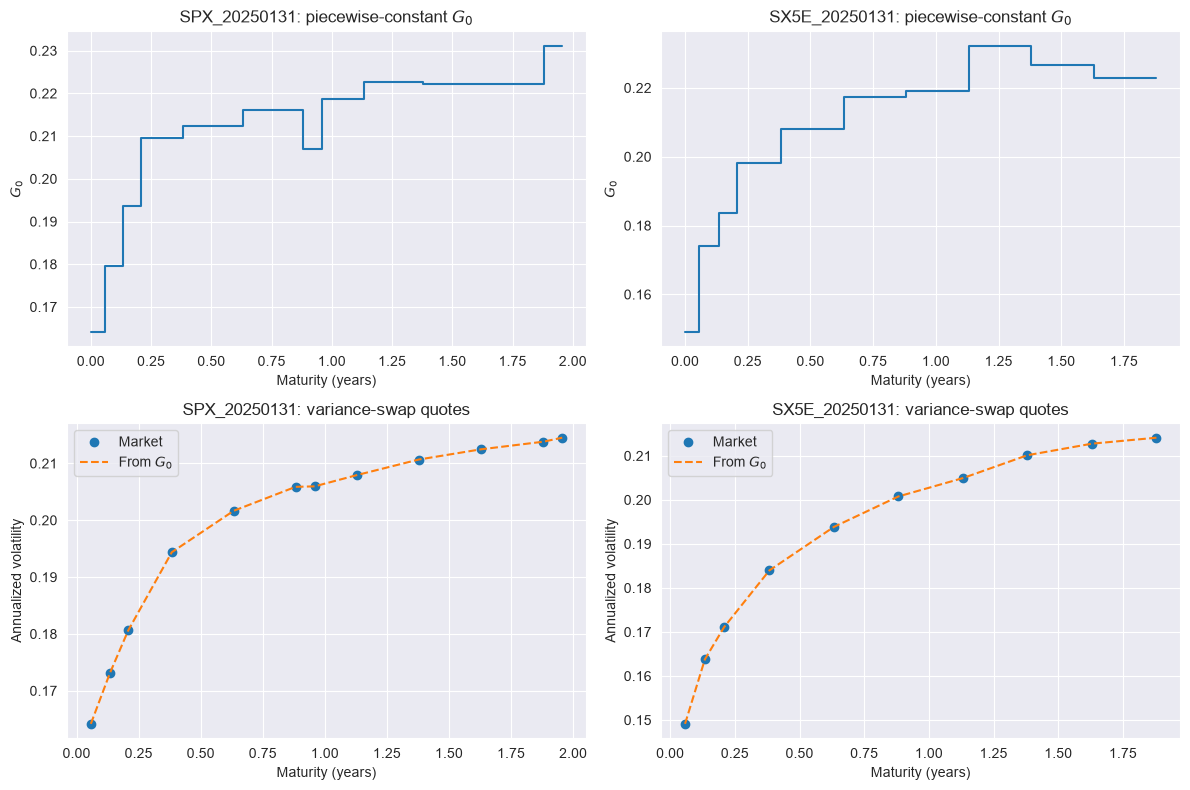

In [32]:
date = '20250131'
fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for column, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    result = g0_results[dataset]
    boundaries = result['time_boundaries']
    values = result['G0_values']
    comparison = result['comparison']
    axes[0, column].step(boundaries, np.r_[values, values[-1]],
                         where='post', label=r'$G_0$')
    axes[0, column].set_title(rf'{dataset}: piecewise-constant $G_0$')
    axes[0, column].set_xlabel('Maturity (years)')
    axes[0, column].set_ylabel(r'$G_0$')
    axes[0, column].grid(True)
    axes[1, column].plot(comparison['maturity'],
                         comparison['variance_swap_quote'], 'o', label='Market')
    axes[1, column].plot(comparison['maturity'],
                         comparison['reconstructed_variance_swap_quote'],
                         '--', label=r'From $G_0$')
    axes[1, column].set_title(f'{dataset}: variance-swap quotes')
    axes[1, column].set_xlabel('Maturity (years)')
    axes[1, column].set_ylabel('Annualized volatility')
    axes[1, column].grid(True)
    axes[1, column].legend()
fig.tight_layout()
target = VARIANCE_SWAP_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(target / 'variance_swap_g0_calibration.png', dpi=200,
            bbox_inches='tight')
plt.show()


## 2025-07-31

In [33]:
for asset in ('SPX_20250731', 'SX5E_20250731'):
    data = clean_variance_swap_data(market_data[asset]['variance_swaps'])
    variance_swap_data[asset] = data

    maturities = data['maturity'].to_numpy(dtype=float)
    market_quotes = data['variance_swap_quote'].to_numpy(dtype=float)

    time_boundaries, G0_values = (
        compute_piecewise_constant_g0_from_variance_swaps(
            maturities,
            market_quotes,
        )
    )

    integrated_variances = np.array([
        integrated_piecewise_constant_g0_squared(
            T, time_boundaries, G0_values
        )
        for T in maturities
    ])
    reconstructed_quotes = np.sqrt(integrated_variances / maturities)

    comparison = data.copy()
    comparison['reconstructed_variance_swap_quote'] = reconstructed_quotes
    comparison['error'] = reconstructed_quotes - market_quotes

    g0_results[asset] = {
        'time_boundaries': time_boundaries,
        'G0_values': G0_values,
        'comparison': comparison,
    }

    print(f'\n{asset} - variance-swap calibration')
    print(f'Maximum reconstruction error: {np.max(np.abs(comparison["error"])):.3e}')



SPX_20250731 - variance-swap calibration
Maximum reconstruction error: 5.551e-17

SX5E_20250731 - variance-swap calibration
Maximum reconstruction error: 2.776e-17


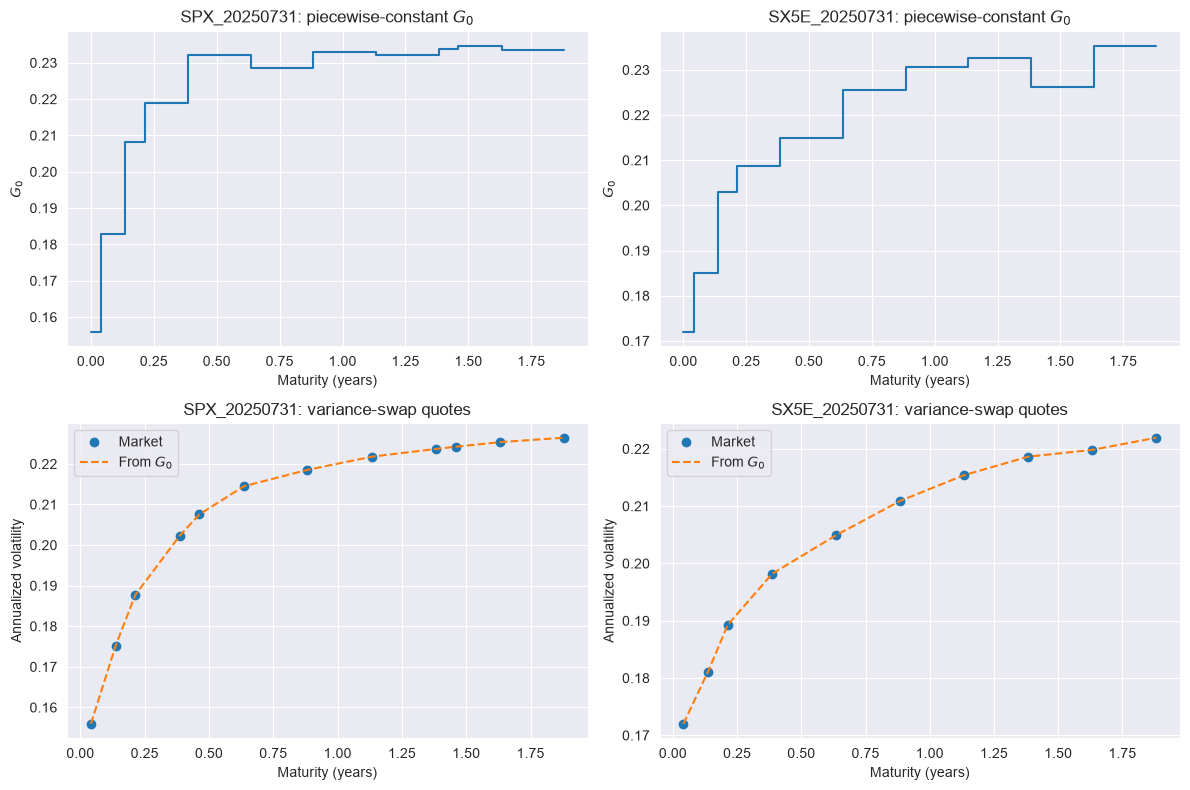

In [34]:
date = '20250731'
fig, axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for column, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'
    result = g0_results[dataset]
    boundaries = result['time_boundaries']
    values = result['G0_values']
    comparison = result['comparison']
    axes[0, column].step(boundaries, np.r_[values, values[-1]],
                         where='post', label=r'$G_0$')
    axes[0, column].set_title(rf'{dataset}: piecewise-constant $G_0$')
    axes[0, column].set_xlabel('Maturity (years)')
    axes[0, column].set_ylabel(r'$G_0$')
    axes[0, column].grid(True)
    axes[1, column].plot(comparison['maturity'],
                         comparison['variance_swap_quote'], 'o', label='Market')
    axes[1, column].plot(comparison['maturity'],
                         comparison['reconstructed_variance_swap_quote'],
                         '--', label=r'From $G_0$')
    axes[1, column].set_title(f'{dataset}: variance-swap quotes')
    axes[1, column].set_xlabel('Maturity (years)')
    axes[1, column].set_ylabel('Annualized volatility')
    axes[1, column].grid(True)
    axes[1, column].legend()
fig.tight_layout()
target = VARIANCE_SWAP_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(target / 'variance_swap_g0_calibration.png', dpi=200,
            bbox_inches='tight')
plt.show()


Pricing by Fourier at maturity $T$ uses the uniform grid $t_i = iT/N$, $i = 0,\dots,N-1$, and requires the values $G_0(t_i)$: for each $i$ we locate the interval
$[T_{k-1}, T_k)$ containing $t_i$ and set

$$
G_0(t_i) = \sqrt{\dfrac{T_k\,\sigma_{\mathrm{VS}}(T_k)^2 - T_{k-1}\,\sigma_{\mathrm{VS}}(T_{k-1})^2}{T_k - T_{k-1}}} .
$$

If $T \ge T_n$ and $i$ is such that $t_i \ge T_n$, the market gives no
information, so we extrapolate flat: $G_0(t_i)$ equals the value of $G_0$ on the last interval
$[T_{n-1}, T_n)$. This is done by the function `evaluate_piecewise_constant_g0_on_grid`.

In [ ]:
asset = next(iter(g0_results))
result = g0_results[asset]

# Use a maturity beyond the last market maturity to show flat extrapolation.
T = 1.25 * result['time_boundaries'][-1]
N = 30
time_grid = np.arange(N) * T / N
G0_grid = evaluate_piecewise_constant_g0_on_grid(
    T,
    N,
    result['time_boundaries'],
    result['G0_values'],
).reshape(-1)

plt.figure(figsize=(7, 3.5))
plt.step(time_grid, G0_grid, where='post', label=r'$G_0$ on Fourier grid')
plt.scatter(time_grid, G0_grid, s=18, zorder=3)
plt.axvline(
    result['time_boundaries'][-1],
    color='black',
    linestyle='--',
    label='Last market maturity',
)
plt.title(rf'{asset}: $G_0$ values used for Fourier pricing')
plt.xlabel('Time (years)')
plt.ylabel(r'$G_0$')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ATM skew and volatility-swap term-structure calibration

## Common one-dimensional model setup

The one-dimensional model setup is the same as in the HSBC notebook. In the
model, $S_0=F_T=1$ with zero rates and a martingale asset price. Hence the
model log-forward-moneyness is exactly $k=\log(K/F_T)=\log K$. We keep
$Y_0=1$ fixed and evaluate model and market skew at $\log(0.99)$ and
$\log(1.01)$. The volatility-swap price is independent of the price–volatility
correlation $c$.

In [35]:
from vss.parameters import compute_tilde_Gamma

n = d = 1
S_0 = 1.0
Y0_VALUE = 1.0

rho = np.array([[1.0]])
R_W = np.array([[1.0]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(
    n=n,
    d=d,
    Gamma=Gamma,
)

log_moneyness = np.log(np.array([0.99, 1.01]))
SKEW_MONEYNESS = np.exp(log_moneyness)
strikes = S_0 * SKEW_MONEYNESS


def log_absolute_skew_residuals(model_skews, market_skews):
    """Return logarithmic residuals for absolute ATM skews."""

    model_skews = np.asarray(model_skews, dtype=float)
    market_skews = np.asarray(market_skews, dtype=float)
    if (
        not np.all(np.isfinite(model_skews))
        or not np.all(np.isfinite(market_skews))
        or np.any(np.abs(model_skews) <= 0.0)
        or np.any(np.abs(market_skews) <= 0.0)
    ):
        raise ValueError(
            'The absolute ATM skews must be finite and strictly positive '
            'before applying the logarithm.'
        )
    return np.log(np.abs(model_skews)) - np.log(np.abs(market_skews))

## Market ATM skew and volatility-swap quotes

For each maturity the workbook supplies exactly two implied volatilities at
$k_-=\log(0.99)$ and $k_+=\log(1.01)$. The signed market ATM-skew estimate is

$$\mathrm{skew}(T)=\frac{\sigma_{\mathrm{impl}}(T,k_+)-
\sigma_{\mathrm{impl}}(T,k_-)}{k_+-k_-}.$$

No additional interpolation or maturity filter is applied. The calibration
minimizes errors in the logarithms of the **absolute** skews, as in the HSBC
notebook. Only the SPX workbooks contain annualized volatility-swap quotes.

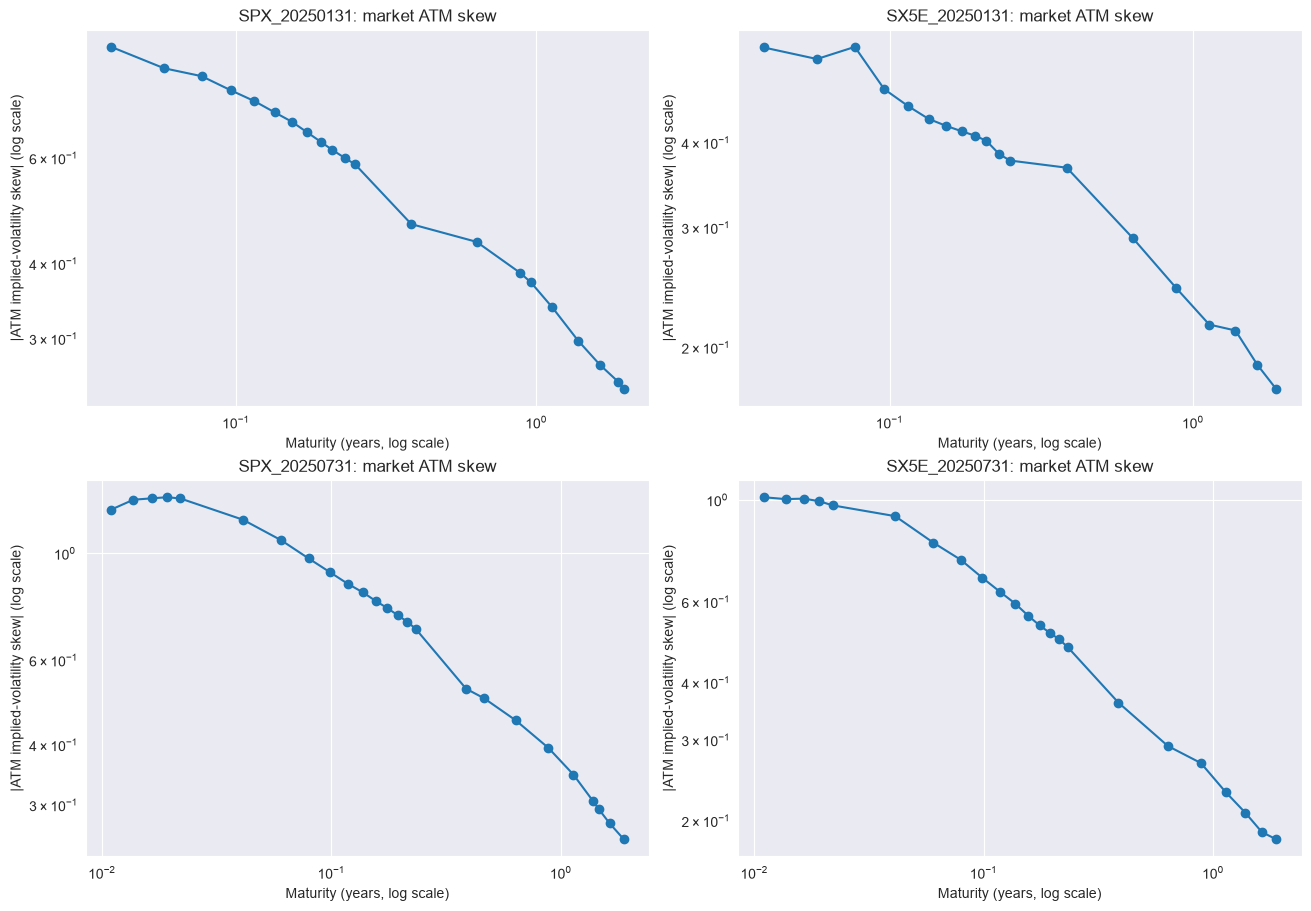

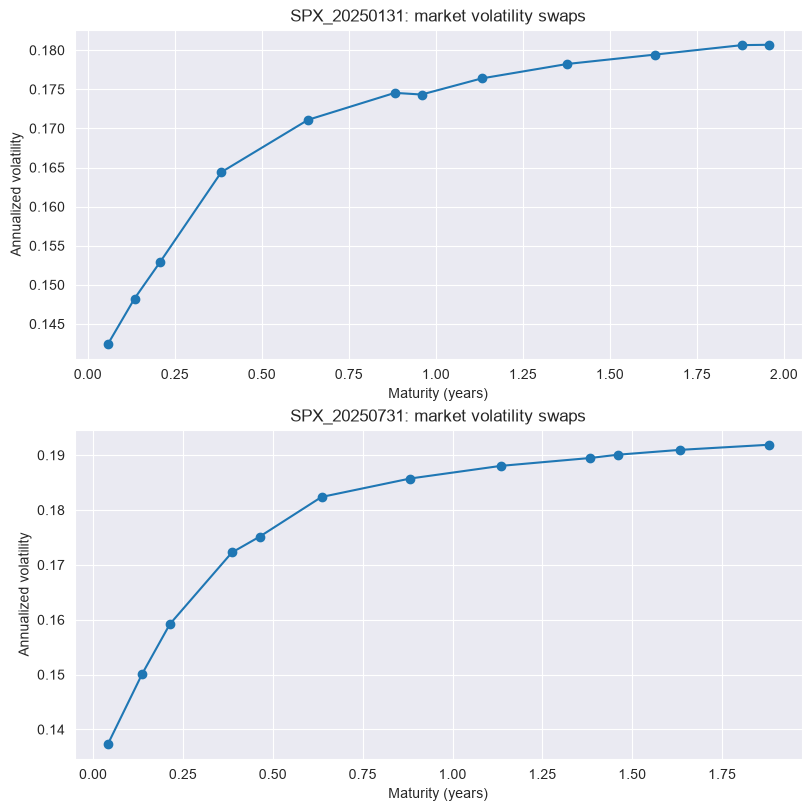

In [36]:
from vss.market_data.skew import compute_market_skew
from vss.market_data.volatility_swap_processing import clean_volatility_swap_data

market_skew_maturities = {}
market_skews = {}
market_implied_volatilities = {}
volatility_swap_data = {}
market_volatility_swap_quotes = {}

for dataset, sheets in market_data.items():
    surface = sheets['implied_volatility']
    maturities = surface.index.to_numpy(dtype=float)
    observed_moneyness = surface.columns.to_numpy(dtype=float)
    if surface.shape[1] != 2 or not np.allclose(
        np.log(observed_moneyness), log_moneyness, rtol=0.0, atol=1e-12
    ):
        raise ValueError(f'{dataset}: expected only 99% and 101% forward moneyness')
    values = surface.to_numpy(dtype=float)
    if not (np.isfinite(values).all() and np.all(values > 0)
            and np.isfinite(maturities).all() and np.all(maturities > 0)):
        raise ValueError(f'{dataset}: invalid implied-volatility observations')
    market_skew_maturities[dataset] = maturities
    market_implied_volatilities[dataset] = values
    market_skews[dataset] = compute_market_skew(
        maturities, log_moneyness, values
    )

    if 'volatility_swaps' in sheets:
        data = clean_volatility_swap_data(sheets['volatility_swaps'])
        volatility_swap_data[dataset] = data.reset_index(drop=True)
        market_volatility_swap_quotes[dataset] = (
            data['volatility_swap_quote'].to_numpy(dtype=float)
        )

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for row, date in enumerate(DATES):
    for column, asset_label in enumerate(('SPX', 'SX5E')):
        dataset = f'{asset_label}_{date}'
        axis = axes[row, column]
        axis.loglog(market_skew_maturities[dataset],
                    np.abs(market_skews[dataset]), 'o-')
        axis.set_title(f'{dataset}: market ATM skew')
        axis.set_xlabel('Maturity (years, log scale)')
        axis.set_ylabel('|ATM implied-volatility skew| (log scale)')
        axis.grid(True)
fig.savefig(MARKET_QUOTES_PLOTS_DIRECTORY / 'market_atm_skew_term_structures.png',
            dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(8, 8), layout='constrained')
for axis, date in zip(axes, DATES):
    dataset = f'SPX_{date}'
    data = volatility_swap_data[dataset]
    axis.plot(data['maturity'], data['volatility_swap_quote'], 'o-')
    axis.set_title(f'{dataset}: market volatility swaps')
    axis.set_xlabel('Maturity (years)')
    axis.set_ylabel('Annualized volatility')
    axis.grid(True)
fig.savefig(MARKET_QUOTES_PLOTS_DIRECTORY / 'market_spx_volatility_swaps.png',
            dpi=200, bbox_inches='tight')
plt.show()

The following plots also show the two observed forward-moneyness volatility curves used for each skew; these are the prepared market points themselves.

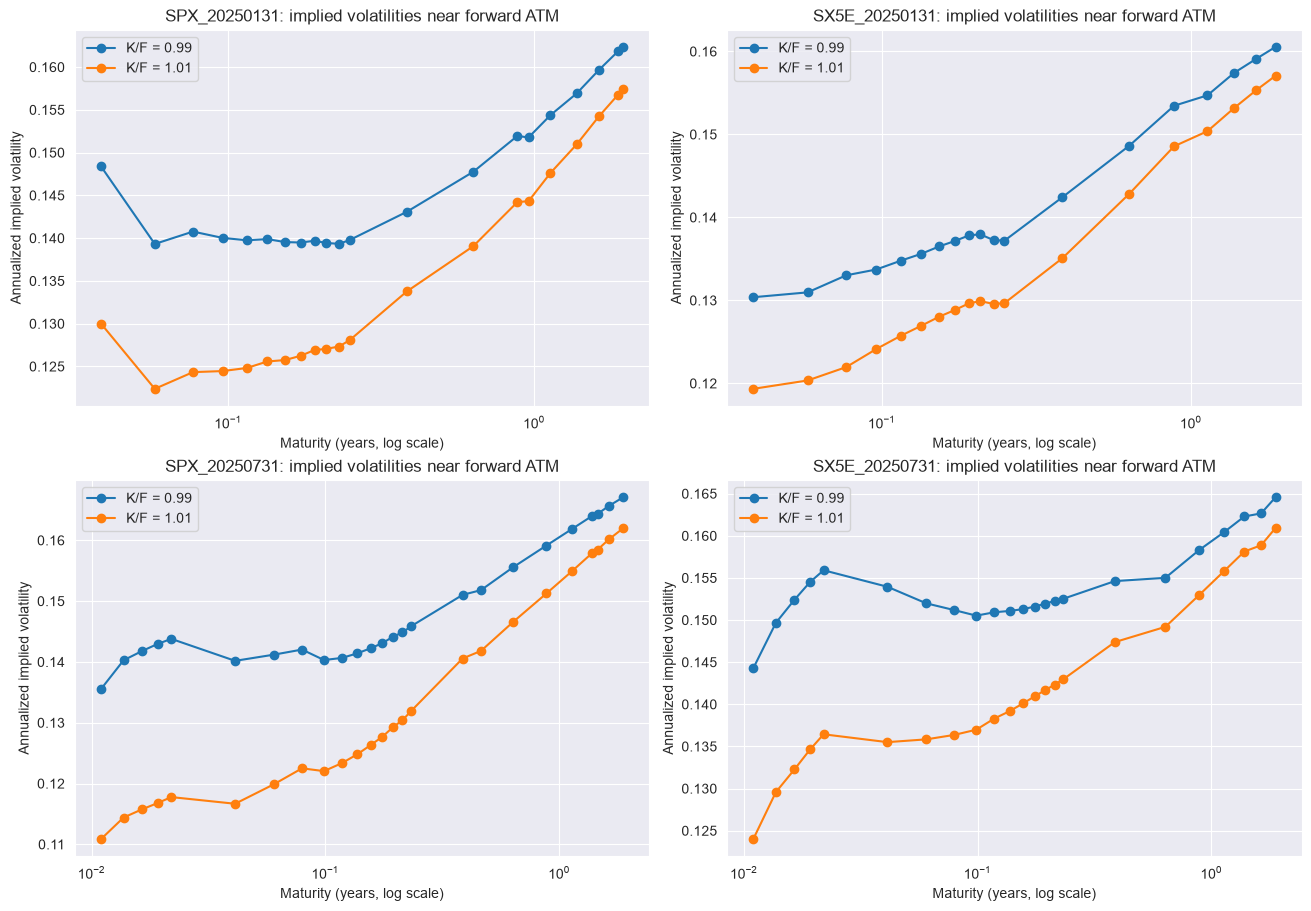

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for row, date in enumerate(DATES):
    for column, asset_label in enumerate(('SPX', 'SX5E')):
        dataset = f'{asset_label}_{date}'
        axis = axes[row, column]
        values = market_implied_volatilities[dataset]
        for j, moneyness in enumerate(SKEW_MONEYNESS):
            axis.semilogx(market_skew_maturities[dataset], values[:, j],
                          'o-', label=f'K/F = {moneyness:.2f}')
        axis.set_title(f'{dataset}: implied volatilities near forward ATM')
        axis.set_xlabel('Maturity (years, log scale)')
        axis.set_ylabel('Annualized implied volatility')
        axis.grid(True)
        axis.legend()
fig.savefig(MARKET_QUOTES_PLOTS_DIRECTORY / 'market_near_atm_implied_volatilities.png',
            dpi=200, bbox_inches='tight')
plt.show()

## Fourier numerical settings

The time-grid resolution and the Gauss-Laguerre quadrature degree must depend on the maturity to obtain sufficiently precise prices.

In [38]:
def fourier_time_gride_and_laguerre_rule_size(T):
    """Return the time-grid size and Laguerre degree for maturity T."""

    if T <= 0.01:
        N_time_steps, Q_laguerre = 20, 128
    elif T <= 0.10:
        N_time_steps, Q_laguerre = 30, 80
    elif T <= 0.50:
        N_time_steps, Q_laguerre = 40, 60
    elif T <= 1.0:
        N_time_steps, Q_laguerre = 50, 40
    else:
        N_time_steps, Q_laguerre = 80, 30

    return N_time_steps, Q_laguerre

In [39]:
def fourier_fractional_time_gride_and_laguerre_rule_size(T, H):
    """Return N and Q adapted to maturity T and fractional parameter H.

    For larger maturities or smaller H, the time discretization must be
    finer, so N is increased. At the same time, the Fourier-Laplace
    transforms decay faster, so fewer Gauss-Laguerre points are needed.
    """

    if not np.isfinite(T) or T <= 0.0:
        raise ValueError("T must be finite and strictly positive.")
    if not np.isfinite(H) or H <= 0.0:
        raise ValueError("H must be finite and strictly positive.")

    # Start from the generic maturity-dependent rule.
    N_base, Q_base = fourier_time_gride_and_laguerre_rule_size(T)

    # Smaller H means a rougher fractional kernel.
    if H <= 0.10:
        N_multiplier, Q_multiplier = 2.0, 0.50
    elif H <= 0.25:
        N_multiplier, Q_multiplier = 1.5, 0.75
    else:
        N_multiplier, Q_multiplier = 1.0, 1.0

    N_time_steps = int(np.ceil(N_base * N_multiplier))
    Q_laguerre = int(np.floor(Q_base * Q_multiplier))

    # Keep a minimum quadrature degree.
    Q_laguerre = max(Q_laguerre, 20)

    return N_time_steps, Q_laguerre

## Calibration plot helper

Each kernel produces market-versus-model ATM-skew plots for all four datasets.
The two SPX plots for each date also show the market-versus-model
volatility-swap term structure; SX5E has only the skew panel. Plot paths
include the valuation date, so the two snapshots never overwrite one another.

In [40]:
def plot_kernel_calibration(dataset, kernel_name, file_stem,
                            atm_results, vol_results):
    atm_result = atm_results[dataset]
    vol_result = vol_results.get(dataset)
    fig, axes = plt.subplots(1, 2 if vol_result is not None else 1,
                             figsize=(14 if vol_result is not None else 7, 5))
    if vol_result is None:
        axes = [axes]
    axes[0].loglog(atm_result['maturities'],
                   np.abs(atm_result['market_skews']), 'o', label='Market')
    axes[0].loglog(atm_result['maturities'],
                   np.abs(atm_result['model_skews']), '-s', markersize=4,
                   label='Model')
    atm_text = ', '.join(f'{name}={value:.2g}' for name, value in zip(
        atm_result['parameter_names'], atm_result['parameters']))
    axes[0].set_title(
        f'{dataset} ATM skew: {kernel_name}\n'
        f'K/F = (0.99, 1.01); {atm_text}, Y0={Y0_VALUE:g} (fixed)'
    )
    axes[0].set_xlabel('Maturity (years, log scale)')
    axes[0].set_ylabel('|ATM skew| (log scale)')
    axes[0].grid(True)
    axes[0].legend()
    if vol_result is not None:
        axes[1].plot(vol_result['maturities'],
                     vol_result['market_quotes'], 'o', label='Market')
        axes[1].plot(vol_result['maturities'],
                     vol_result['model_quotes'], '-s', markersize=4,
                     label='Model')
        vol_text = ', '.join(f'{name}={value:.2g}' for name, value in zip(
            vol_result['parameter_names'], vol_result['parameters']))
        axes[1].set_title(
            f'{dataset} volatility swap: {kernel_name}\n'
            f'{vol_text}, Y0={Y0_VALUE:g} (fixed)'
        )
        axes[1].set_xlabel('Maturity (years)')
        axes[1].set_ylabel('Annualized volatility')
        axes[1].grid(True)
        axes[1].legend()
    fig.tight_layout()
    target = ATM_SKEW_PLOTS_DIRECTORY / dataset.split('_')[1]
    target.mkdir(parents=True, exist_ok=True)
    fig.savefig(target / f'{dataset}_{file_stem}_calibration.png',
                dpi=200, bbox_inches='tight')
    plt.show()
    rows = []
    for calibration_type, result in [
        ('ATM skew', atm_result), ('Volatility swap', vol_result)
    ]:
        if result is None:
            continue
        row = {
            'Dataset': dataset,
            'Calibration': calibration_type,
            'Calibrated parameters': ', '.join(result['parameter_names']),
            'Fixed parameters': f'Y0 = {Y0_VALUE:.6g}',
        }
        if calibration_type == 'ATM skew':
            row['Log-skew RMSE'] = result['log_RMSE']
            row['Maximum log-skew error'] = result['maximum_log_error']
        else:
            row['Absolute RMSE'] = result['RMSE']
            row['Relative RMSE (%)'] = 100 * result['relative_RMSE']
        row.update(dict(zip(result['parameter_names'], result['parameters'])))
        if 'a_1' in row:
            row['a_2'] = 1.0 - row['a_1']
        rows.append(row)
    display(pd.DataFrame(rows))

## Fractional-kernel calibration

We calibrate the fractional kernel separately to the four CACIB index–date datasets. It is obtained from `shifted_fractional_KK_SIG_d1_n1` by setting `delta = 0`. The calibrated ATM-skew parameters are `H`, `eta`, and `C`; the calibrated volatility-swap parameters are `H` and `eta`. In every case, `Y0` is fixed to 1 and `Gamma` is fixed to 1.

Functions prefixed with `fractional_` are specific to the fractional kernel. Functions such as `skew_fourier` and `compute_market_skew` are generic and can be reused with other kernels.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

In [41]:
atm_skew_results = {}
vol_swap_results = {}


def build_fractional_objects(asset, T, N, H, eta, c):
    """Build the matrices and vectors needed for Fourier pricing with fractional kernel."""

    # Build the fractional kernel matrices KK and SIG_eta_free, then scale SIG_eta_free it by eta to obtain SIG.
    KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
        N=N, T=T,
        H=H,
        delta=0.0,
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the previously calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices, then the Fourier covariance objects.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=True):
    """Return the fractional-kernel ATM skew at maturity T.

    If use_adaptive_resolution is False, use the generic Fourier rule.
    This keeps the numerical resolution fixed during calibration.
    """

    H, eta, c = parameters
    if use_adaptive_resolution:
        N, Q_laguerre = fourier_fractional_time_gride_and_laguerre_rule_size(T, H)
    else:
        N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_fractional_objects(
        asset, T, N, H, eta, c
    )
    # The skew formula uses the Fourier transform along the u-contour.
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


def fractional_vol_swap(asset, T, parameters, use_adaptive_resolution=True):
    """Return the fractional-kernel annualized volatility-swap quote at T.

    If use_adaptive_resolution is False, use the generic Fourier rule.
    This keeps the numerical resolution fixed during calibration.
    """

    H, eta = parameters
    if use_adaptive_resolution:
        N, Q_laguerre = fourier_fractional_time_gride_and_laguerre_rule_size(T, H)
    else:
        N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, _ = build_fractional_objects(
        asset, T, N, H, eta, 0.0
    )
    # Volatility swaps use u = 0 and integrate over the variance variable.
    u_array = np.zeros((len(nodes), 1), dtype=complex)
    w_array = (-nodes).reshape(-1, 1, 1).astype(complex)
    # The volatility-swap price is independent of c; use c = 0.
    C_zero = np.array([[0.0]])
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_zero, rho, R_W,
        V, sqrt_V, g_tilde
    )
    g0_result = g0_results[asset]
    # Add the deterministic integrated variance coming from the calibrated G0.
    expected_integrated_variance = integrated_piecewise_constant_g0_squared(
        T, g0_result['time_boundaries'], g0_result['G0_values']
    )
    vol_swap_price = vol_swap_price_fourier(
        transform_values, expected_integrated_variance, nodes, weights
    )
    return vol_swap_price / np.sqrt(T)

### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [83]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.8, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 ATM-skew parameters: [ 0.25968746  0.8        -0.99269752]
SPX_20250131 ATM-skew log RMSE: 3.380e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [84]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250131'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([0.01, 0.01], dtype=float)
upper_bounds = np.array([0.5, 0.8], dtype=float)


def vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_vol_swap(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_vol_swap(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} volatility-swap RMSE: {vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250131 volatility-swap parameters: [0.32405785 0.8       ]
SPX_20250131 volatility-swap RMSE: 1.914e-02


###### Calibration plots

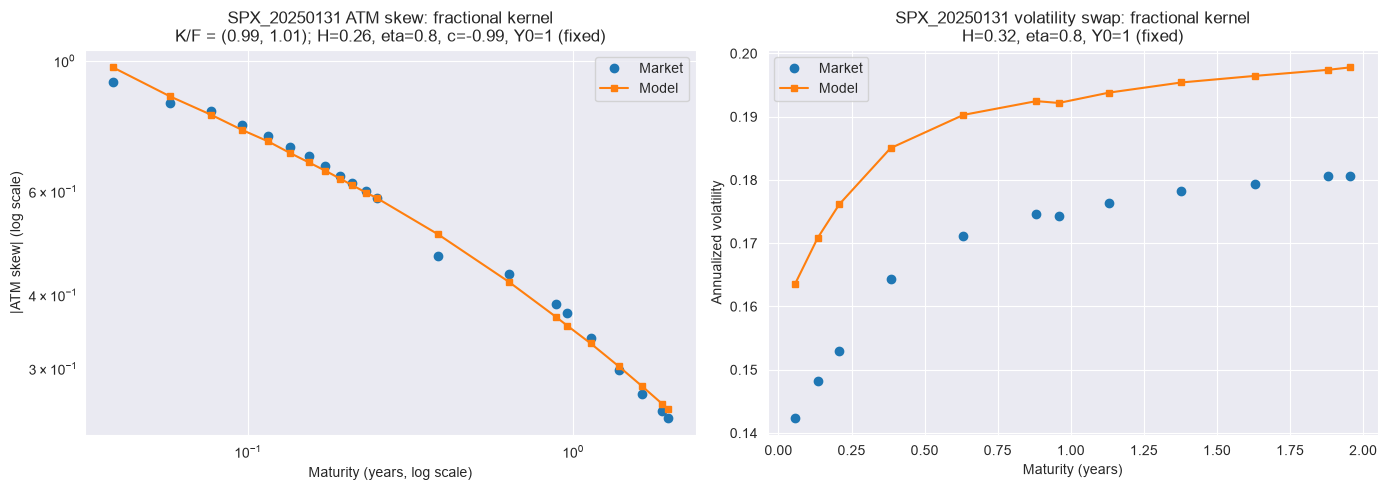

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250131,ATM skew,"H, eta, c",Y0 = 1,0.033805,0.086148,0.259687,0.8,-0.992698,NaN,NaN
1,SPX_20250131,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.324058,0.8,NaN,0.019138,11.669931


In [85]:
dataset = 'SPX_20250131'
plot_kernel_calibration(dataset, 'fractional kernel', 'fractional',
                        atm_skew_results, vol_swap_results)


##### SX5E

###### ATM skew calibration

In [92]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 ATM-skew parameters: [ 0.223744    0.5        -0.84320566]
SX5E_20250131 ATM-skew log RMSE: 5.157e-02


###### Calibration plots

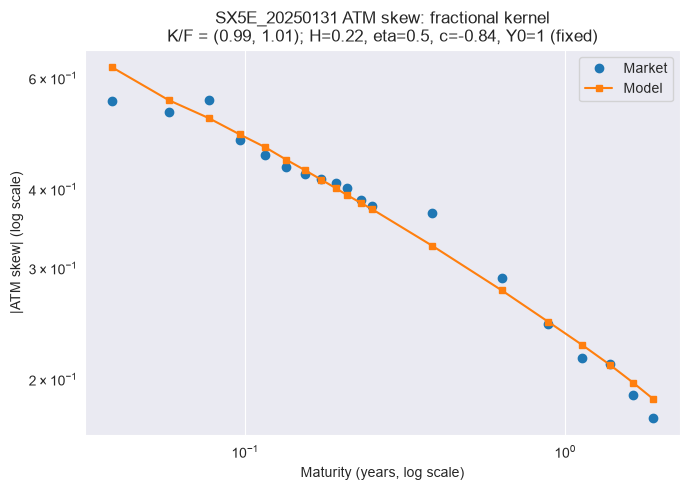

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250131,ATM skew,"H, eta, c",Y0 = 1,0.051566,0.122297,0.223744,0.5,-0.843206


In [93]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(dataset, 'fractional kernel', 'fractional',
                        atm_skew_results, vol_swap_results)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [89]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.95, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 ATM-skew parameters: [ 0.27274478  0.95       -0.99502555]
SPX_20250731 ATM-skew log RMSE: 6.837e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [90]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250731'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([0.01, 0.01], dtype=float)
upper_bounds = np.array([0.5, 0.95], dtype=float)


def vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_vol_swap(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_vol_swap(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} volatility-swap RMSE: {vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250731 volatility-swap parameters: [0.34501385 0.95      ]
SPX_20250731 volatility-swap RMSE: 1.790e-02


###### Calibration plots

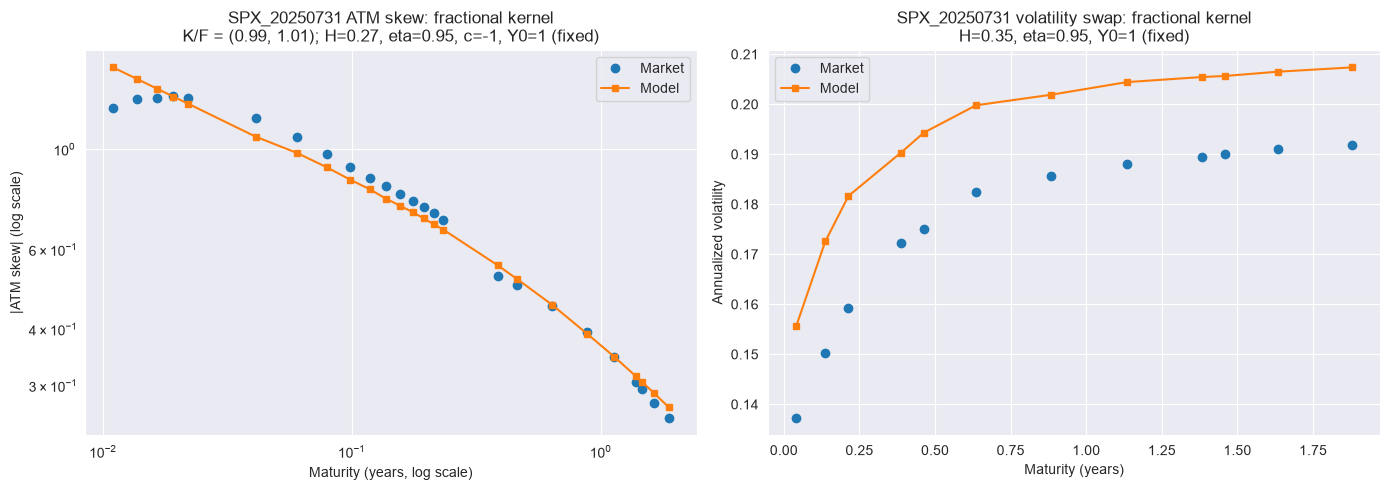

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250731,ATM skew,"H, eta, c",Y0 = 1,0.068368,0.207468,0.272745,0.95,-0.995026,NaN,NaN
1,SPX_20250731,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.345014,0.95,NaN,0.017899,10.570521


In [91]:
dataset = 'SPX_20250731'
plot_kernel_calibration(dataset, 'fractional kernel', 'fractional',
                        atm_skew_results, vol_swap_results)


##### SX5E

###### ATM skew calibration

In [102]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        fractional_atm_skew(asset, T, parameters, use_adaptive_resolution=False)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    fractional_atm_skew(asset, T, calibrated_parameters, use_adaptive_resolution=True)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} ATM-skew log RMSE: {atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 ATM-skew parameters: [ 0.17351136  0.5        -0.95228386]
SX5E_20250731 ATM-skew log RMSE: 1.042e-01


###### Calibration plots

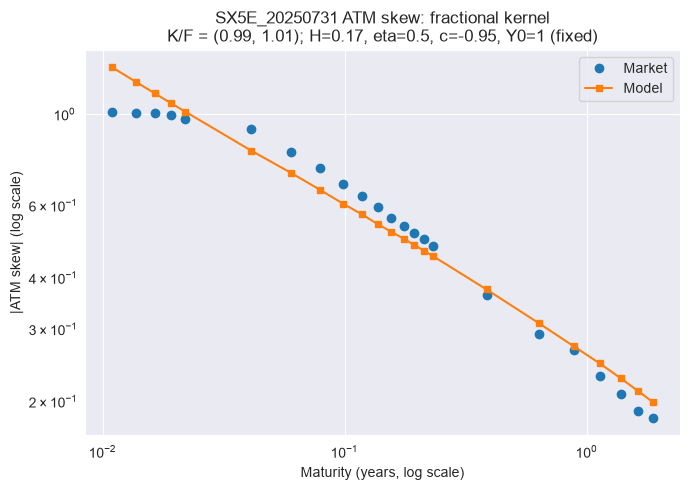

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250731,ATM skew,"H, eta, c",Y0 = 1,0.10417,0.248276,0.173511,0.5,-0.952284


In [103]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(dataset, 'fractional kernel', 'fractional',
                        atm_skew_results, vol_swap_results)


## Shifted fractional-kernel calibration

This section repeats the fixed-$Y_0$ calibration procedure with the shifted fractional kernel, using $\delta=5/252$. The shift makes the kernel smooth, so the generic maturity-dependent Fourier rule is used for both optimization and final evaluation. Functions and results specific to this kernel are prefixed with `shifted_fractional_`.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

The following functions build the shifted-fractional kernel objects and compute the ATM skew and volatility-swap quotes. They reuse the generic Fourier and quadrature functions defined above.

In [48]:
shifted_fractional_atm_skew_results = {}
shifted_fractional_vol_swap_results = {}


SHIFTED_FRACTIONAL_DELTA = 1 / 52.

def build_shifted_fractional_objects(asset, T, N, H, eta, c):
    """Build the Fourier-pricing objects for the shifted fractional kernel."""

    # Build the shifted fractional kernel matrices with delta = 5/252.
    KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
        N=N, T=T,
        H=H,
        delta=SHIFTED_FRACTIONAL_DELTA,
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def shifted_fractional_atm_skew(asset, T, parameters):
    """Return the ATM skew for the shifted fractional kernel."""

    H, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_shifted_fractional_objects(
        asset, T, N, H, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


def shifted_fractional_vol_swap(asset, T, parameters):
    """Return the annualized volatility-swap quote for the shifted fractional kernel."""

    H, eta = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, _ = build_shifted_fractional_objects(
        asset, T, N, H, eta, 0.0
    )

    u_array = np.zeros((len(nodes), 1), dtype=complex)
    w_array = (-nodes).reshape(-1, 1, 1).astype(complex)
    # The volatility-swap price is independent of c; use c = 0.
    C_zero = np.array([[0.0]])
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_zero, rho, R_W,
        V, sqrt_V, g_tilde
    )

    g0_result = g0_results[asset]
    expected_integrated_variance = integrated_piecewise_constant_g0_squared(
        T, g0_result['time_boundaries'], g0_result['G0_values']
    )
    vol_swap_price = vol_swap_price_fourier(
        transform_values, expected_integrated_variance, nodes, weights
    )
    return vol_swap_price / np.sqrt(T)

### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [80]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.1, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.8, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 shifted-fractional ATM-skew parameters: [ 0.14387114  0.78224509 -0.999     ]
SPX_20250131 shifted-fractional ATM-skew log RMSE: 3.234e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [81]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250131'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = shifted_fractional_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([-0.49, 0.01], dtype=float)
upper_bounds = np.array([0.5, 0.8], dtype=float)


def shifted_fractional_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    shifted_fractional_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

shifted_fractional_vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional volatility-swap RMSE: {shifted_fractional_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250131 shifted-fractional volatility-swap parameters: [0.27627859 0.8       ]
SPX_20250131 shifted-fractional volatility-swap RMSE: 1.919e-02


###### Calibration plots

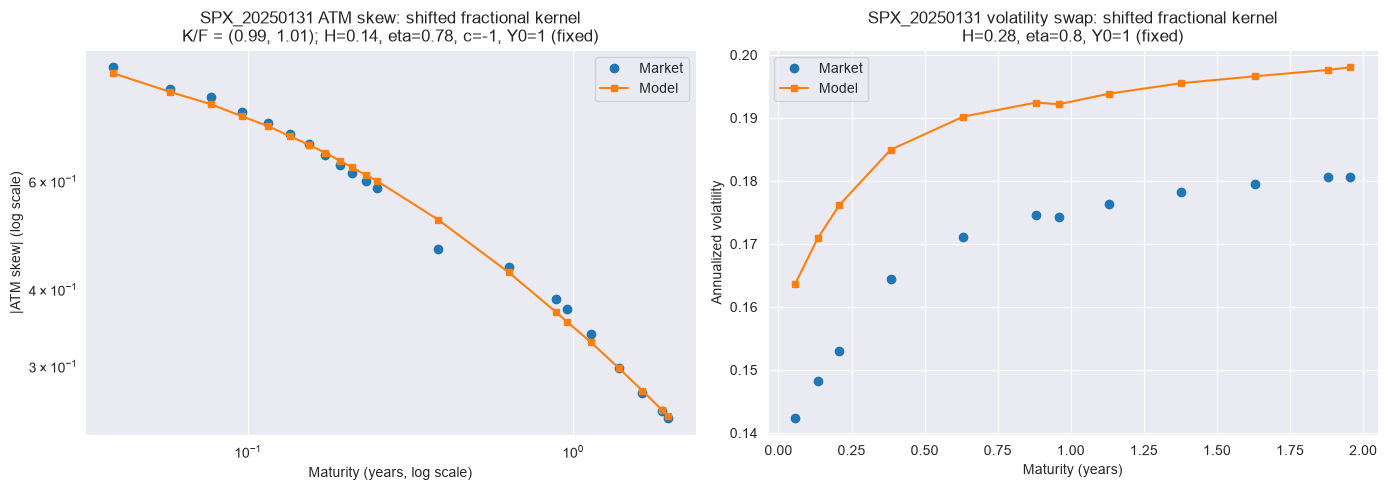

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250131,ATM skew,"H, eta, c",Y0 = 1,0.032342,0.110139,0.143871,0.782245,-0.999,NaN,NaN
1,SPX_20250131,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.276279,0.800000,NaN,0.01919,11.69853


In [82]:
dataset = 'SPX_20250131'
plot_kernel_calibration(dataset, 'shifted fractional kernel', 'shifted_fractional',
                        shifted_fractional_atm_skew_results, shifted_fractional_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [98]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.30, 0.3, -0.8], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 shifted-fractional ATM-skew parameters: [ 0.08924456  0.5        -0.84893586]
SX5E_20250131 shifted-fractional ATM-skew log RMSE: 3.762e-02


###### Calibration plots

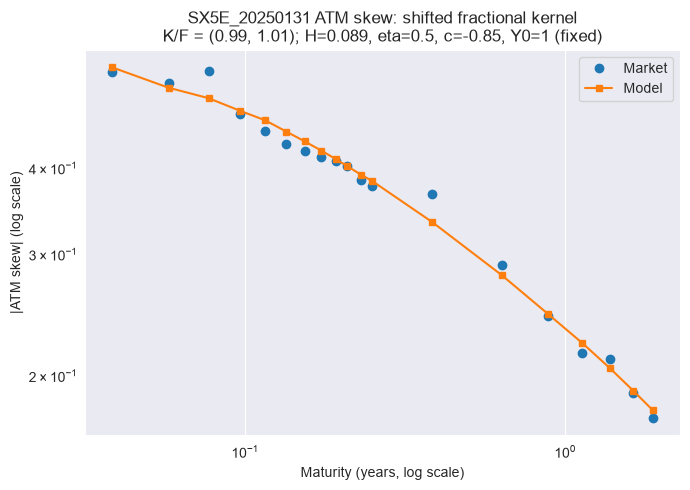

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250131,ATM skew,"H, eta, c",Y0 = 1,0.037623,0.095185,0.089245,0.5,-0.848936


In [99]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(dataset, 'shifted fractional kernel', 'shifted_fractional',
                        shifted_fractional_atm_skew_results, shifted_fractional_vol_swap_results)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [86]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.1, 0.6, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.95, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 shifted-fractional ATM-skew parameters: [ 0.10450227  0.9226168  -0.999     ]
SPX_20250731 shifted-fractional ATM-skew log RMSE: 3.570e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [87]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250731'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = shifted_fractional_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([-0.49, 0.01], dtype=float)
upper_bounds = np.array([0.5, 0.95], dtype=float)


def shifted_fractional_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    shifted_fractional_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

shifted_fractional_vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional volatility-swap RMSE: {shifted_fractional_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250731 shifted-fractional volatility-swap parameters: [0.29284415 0.95      ]
SPX_20250731 shifted-fractional volatility-swap RMSE: 1.790e-02


###### Calibration plots

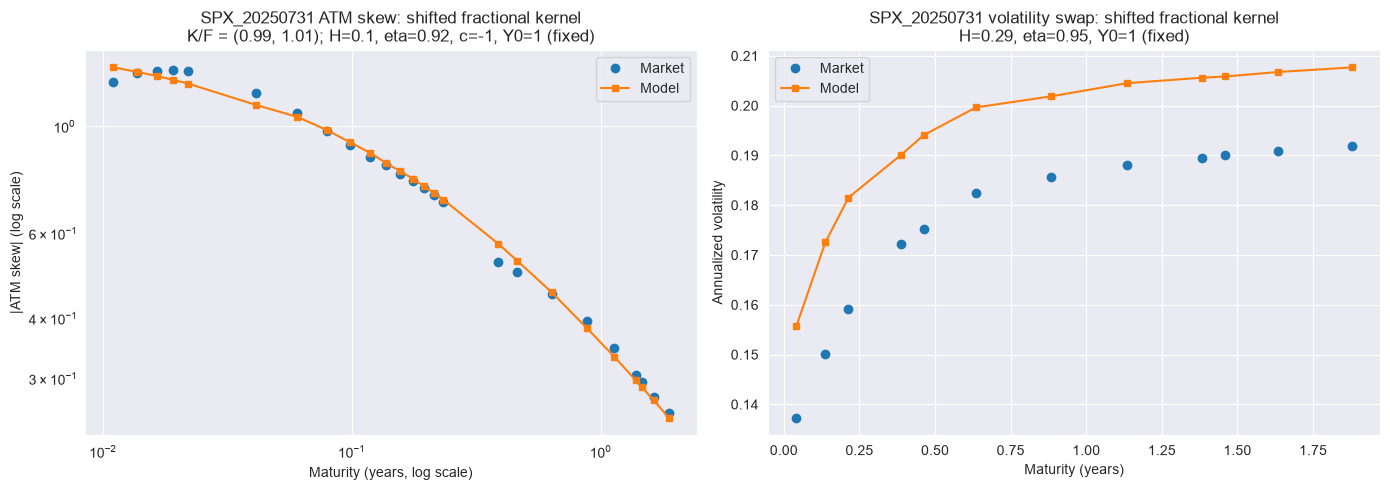

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250731,ATM skew,"H, eta, c",Y0 = 1,0.035699,0.088478,0.104502,0.922617,-0.999,NaN,NaN
1,SPX_20250731,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.292844,0.950000,NaN,0.017896,10.561197


In [88]:
dataset = 'SPX_20250731'
plot_kernel_calibration(dataset, 'shifted fractional kernel', 'shifted_fractional',
                        shifted_fractional_atm_skew_results, shifted_fractional_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [100]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.30, 0.3, -0.8], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.5, 0.9, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def shifted_fractional_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        shifted_fractional_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    shifted_fractional_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    shifted_fractional_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

shifted_fractional_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} shifted-fractional ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} shifted-fractional ATM-skew log RMSE: {shifted_fractional_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 shifted-fractional ATM-skew parameters: [-0.11622145  0.49323834 -0.999     ]
SX5E_20250731 shifted-fractional ATM-skew log RMSE: 3.708e-02


###### Calibration plots

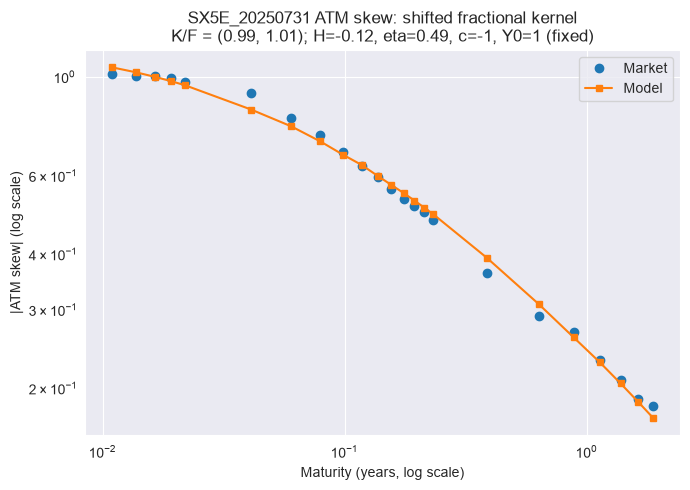

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250731,ATM skew,"H, eta, c",Y0 = 1,0.037076,0.087945,-0.116221,0.493238,-0.999


In [101]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(dataset, 'shifted fractional kernel', 'shifted_fractional',
                        shifted_fractional_atm_skew_results, shifted_fractional_vol_swap_results)


## One-exponential-kernel calibration

This section repeats the fixed-$Y_0$ calibration procedure with the one-exponential kernel $K(t,s)=\mathbf{1}_{s<t}\dfrac{\delta^{H-1/2}}{\Gamma(H+1/2)}\exp\left(-\dfrac{1/2-H}{\delta}(t-s)\right)$, using $\delta=5/252$. Equivalently, with $\kappa=(1/2-H)/\delta$, its shape is proportional to $\delta^{-\kappa\delta}\exp(-\kappa(t-s))$. The calibrated kernel-shape parameter is $H$. Functions and results specific to this kernel are prefixed with `one_exp_`.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

The following functions build the one-exponential kernel objects and compute the ATM skew and volatility-swap quotes. They reuse the generic Fourier and quadrature functions defined above.

In [106]:
one_exp_atm_skew_results = {}
one_exp_vol_swap_results = {}


from vss.kernels.one_asset.sum_exponential import sum_exponential_KK_SIG_d1_n1

ONE_EXP_DELTA = 5/252


def one_exp_kernel_parameters(H):
    """Return the exponential rate and weight implied by H."""

    kappa = (0.5 - H) / ONE_EXP_DELTA
    if abs(kappa) < 1e-8:
        kappa = 0.0
    weight = ONE_EXP_DELTA ** (H - 0.5) / gamma(H + 0.5)
    return kappa, weight


def build_one_exp_objects(asset, T, N, H, eta, c):
    """Build the Fourier-pricing objects for the one-exponential kernel."""

    kappa, weight = one_exp_kernel_parameters(H)

    # Build the paper-inspired exponential kernel with H-implied weight and rate.
    KK, SIG_eta_free = sum_exponential_KK_SIG_d1_n1(
        N=N, T=T,
        kappa_array=np.array([[kappa]]),
        c_array=np.array([[weight]]),
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def one_exp_atm_skew(asset, T, parameters):
    """Return the ATM skew for the one-exponential kernel."""

    H, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_one_exp_objects(
        asset, T, N, H, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


def one_exp_vol_swap(asset, T, parameters):
    """Return the annualized volatility-swap quote for the one-exponential kernel."""

    H, eta = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, _ = build_one_exp_objects(
        asset, T, N, H, eta, 0.0
    )

    u_array = np.zeros((len(nodes), 1), dtype=complex)
    w_array = (-nodes).reshape(-1, 1, 1).astype(complex)
    # The volatility-swap price is independent of c; use c = 0.
    C_zero = np.array([[0.0]])
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_zero, rho, R_W,
        V, sqrt_V, g_tilde
    )

    g0_result = g0_results[asset]
    expected_integrated_variance = integrated_piecewise_constant_g0_squared(
        T, g0_result['time_boundaries'], g0_result['G0_values']
    )
    vol_swap_price = vol_swap_price_fourier(
        transform_values, expected_integrated_variance, nodes, weights
    )
    return vol_swap_price / np.sqrt(T)

### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [159]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.1, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.50, 2.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 one-exponential ATM-skew parameters: [ 0.5         2.15006212 -0.82356401]
SPX_20250131 one-exponential ATM-skew log RMSE: 6.156e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [160]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250131'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = one_exp_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([-0.49, 0.01], dtype=float)
upper_bounds = np.array([0.50, 2.5], dtype=float)


def one_exp_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    one_exp_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

one_exp_vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} one-exponential volatility-swap RMSE: {one_exp_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250131 one-exponential volatility-swap parameters: [0.5        2.49998133]
SPX_20250131 one-exponential volatility-swap RMSE: 1.438e-02


###### Calibration plots

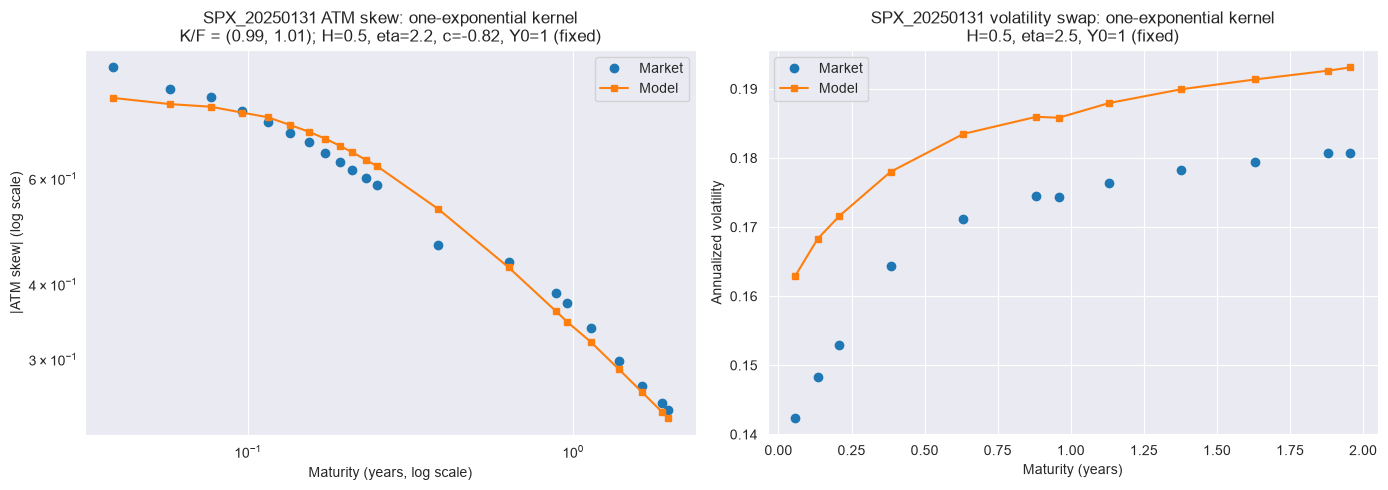

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250131,ATM skew,"H, eta, c",Y0 = 1,0.061563,0.137786,0.5,2.150062,-0.823564,NaN,NaN
1,SPX_20250131,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.5,2.499981,NaN,0.014383,8.981357


In [161]:
dataset = 'SPX_20250131'
plot_kernel_calibration(dataset, 'one-exponential kernel', 'one_exp',
                        one_exp_atm_skew_results, one_exp_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [142]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([-0.1, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.50, 1.5, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 one-exponential ATM-skew parameters: [ 0.4527621   0.88742765 -0.999     ]
SX5E_20250131 one-exponential ATM-skew log RMSE: 7.826e-02


###### Calibration plots

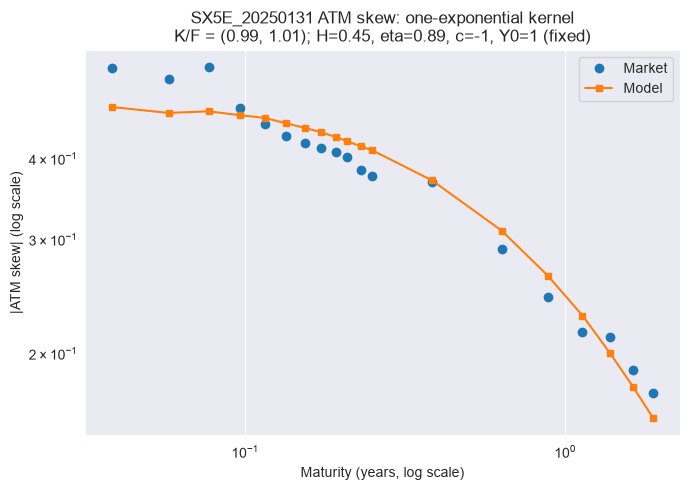

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250131,ATM skew,"H, eta, c",Y0 = 1,0.078263,0.156306,0.452762,0.887428,-0.999


In [143]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(dataset, 'one-exponential kernel', 'one_exp',
                        one_exp_atm_skew_results, one_exp_vol_swap_results)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [165]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.1, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.50, 3., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 one-exponential ATM-skew parameters: [ 0.49790041  3.         -0.84974119]
SPX_20250731 one-exponential ATM-skew log RMSE: 5.708e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [166]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250731'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = one_exp_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1]].copy()
lower_bounds = np.array([-0.49, 0.01], dtype=float)
upper_bounds = np.array([0.50, 3.], dtype=float)


def one_exp_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    one_exp_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

one_exp_vol_swap_results[asset] = {
    'parameter_names': ['H', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} one-exponential volatility-swap RMSE: {one_exp_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250731 one-exponential volatility-swap parameters: [0.49999988 3.        ]
SPX_20250731 one-exponential volatility-swap RMSE: 1.355e-02


###### Calibration plots

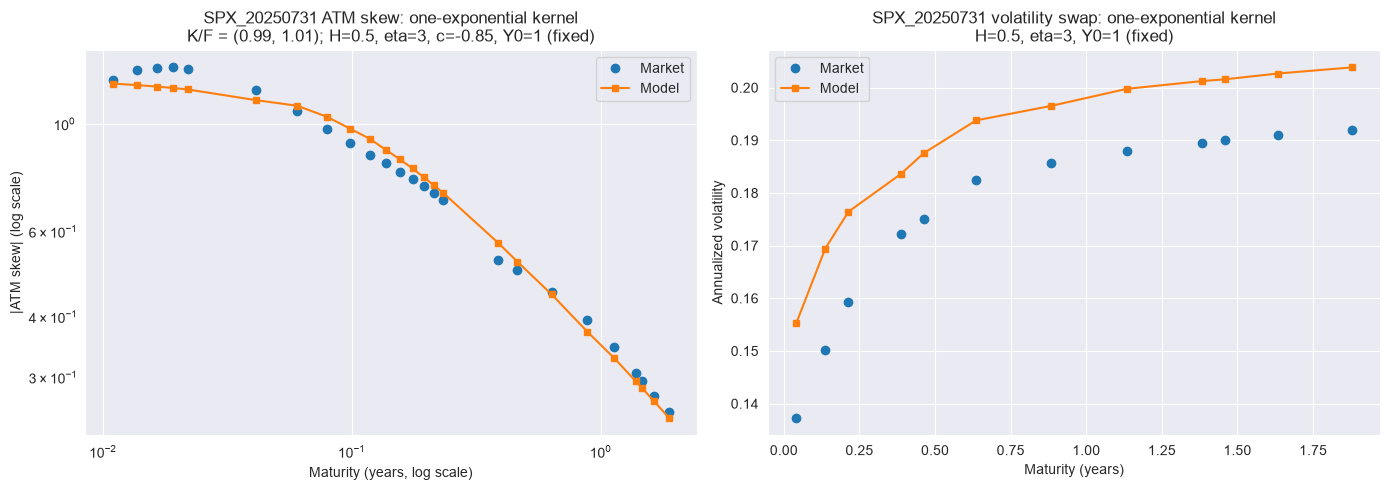

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c,Absolute RMSE,Relative RMSE (%)
0,SPX_20250731,ATM skew,"H, eta, c",Y0 = 1,0.057076,0.099331,0.4979,3.0,-0.849741,NaN,NaN
1,SPX_20250731,Volatility swap,"H, eta",Y0 = 1,NaN,NaN,0.5000,3.0,NaN,0.013553,8.207687


In [167]:
dataset = 'SPX_20250731'
plot_kernel_calibration(dataset, 'one-exponential kernel', 'one_exp',
                        one_exp_atm_skew_results, one_exp_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [150]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.3, 0.3, -0.80], dtype=float)
lower_bounds = np.array([-0.49, 0.01, -0.999], dtype=float)
upper_bounds = np.array([0.50, 3.1, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def one_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        one_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    one_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    one_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

one_exp_atm_skew_results[asset] = {
    'parameter_names': ['H', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} one-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} one-exponential ATM-skew log RMSE: {one_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 one-exponential ATM-skew parameters: [ 0.49110979  3.1        -0.62984476]
SX5E_20250731 one-exponential ATM-skew log RMSE: 6.018e-02


###### Calibration plots

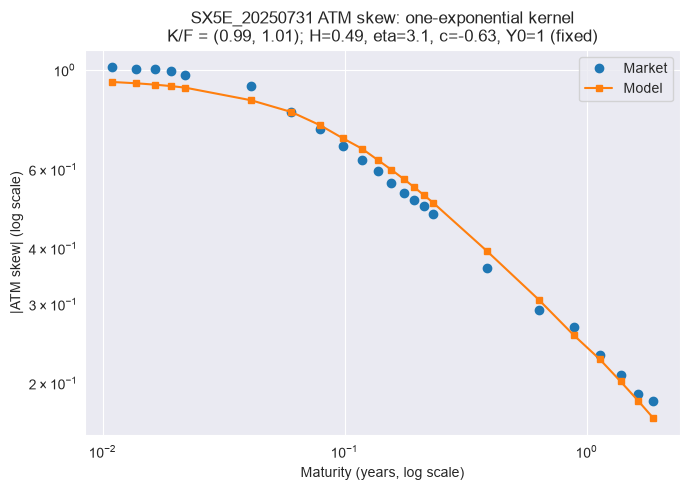

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,H,eta,c
0,SX5E_20250731,ATM skew,"H, eta, c",Y0 = 1,0.060175,0.087681,0.49111,3.1,-0.629845


In [151]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(dataset, 'one-exponential kernel', 'one_exp',
                        one_exp_atm_skew_results, one_exp_vol_swap_results)


## Two-exponential-kernel calibration

This section repeats the fixed-$Y_0$ calibration procedure with a sum of two exponential kernels. The kernel is $K(t,s)=\mathbf{1}_{s<t}[a_1\exp(-\kappa_1(t-s))+a_2\exp(-\kappa_2(t-s))]$, with $a_2=1-a_1$. Functions and results specific to this kernel are prefixed with `two_exp_`.

**Prerequisites:** data extraction, the $G_0$ calibration, the common one-dimensional setup, market targets, and Fourier numerical settings.

### General functions

The following functions build the two-exponential kernel objects and compute the ATM skew and volatility-swap quotes. They reuse the generic Fourier and quadrature functions defined above.

In [129]:
two_exp_atm_skew_results = {}
two_exp_vol_swap_results = {}


from vss.kernels.one_asset.sum_exponential import sum_exponential_KK_SIG_d1_n1

def build_two_exp_objects(asset, T, N, kappa_1, kappa_2, a_1, eta, c):
    """Build the Fourier-pricing objects for the two-exponential kernel."""

    a_2 = 1.0 - a_1
    # Keep the rate-weight pairs aligned when the two rates are reordered.
    if kappa_1 > kappa_2:
        kappa_1, kappa_2 = kappa_2, kappa_1
        a_1, a_2 = a_2, a_1

    # Build the two-exponential kernel with normalized weights a_1 + a_2 = 1.
    KK, SIG_eta_free = sum_exponential_KK_SIG_d1_n1(
        N=N, T=T,
        kappa_array=np.array([[kappa_1, kappa_2]]),
        c_array=np.array([[a_1, a_2]]),
    )

    eta_matrix = np.array([[eta]])
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]])
    Y0_array = np.array([Y0_VALUE])

    # Reuse the calibrated piecewise-constant G0 curve.
    g0_result = g0_results[asset]
    G0_grid = evaluate_piecewise_constant_g0_on_grid(
        T, N, g0_result['time_boundaries'], g0_result['G0_values']
    )

    # Assemble the model matrices used by the Fourier transform.
    MM = compute_M_matrix(
        n=n, d=d, N=N, SIG=SIG, Gamma=Gamma,
        tilde_Gamma=tilde_Gamma, rho=rho, G0=G0_grid, Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(n, N, T, eta_matrix, R_W, KK, SIG, MM)
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


def two_exp_atm_skew(asset, T, parameters):
    """Return the ATM skew for the two-exponential kernel."""

    kappa_1, kappa_2, a_1, eta, c = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, C_matrix = build_two_exp_objects(
        asset, T, N, kappa_1, kappa_2, a_1, eta, c
    )

    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness, nodes, weights
    )


def two_exp_vol_swap(asset, T, parameters):
    """Return the annualized volatility-swap quote for the two-exponential kernel."""

    kappa_1, kappa_2, a_1, eta = parameters
    N, Q_laguerre = fourier_time_gride_and_laguerre_rule_size(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    V, sqrt_V, g_tilde, _ = build_two_exp_objects(
        asset, T, N, kappa_1, kappa_2, a_1, eta, 0.0
    )

    u_array = np.zeros((len(nodes), 1), dtype=complex)
    w_array = (-nodes).reshape(-1, 1, 1).astype(complex)
    # The volatility-swap price is independent of c; use c = 0.
    C_zero = np.array([[0.0]])
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_zero, rho, R_W,
        V, sqrt_V, g_tilde
    )

    g0_result = g0_results[asset]
    expected_integrated_variance = integrated_piecewise_constant_g0_squared(
        T, g0_result['time_boundaries'], g0_result['G0_values']
    )
    vol_swap_price = vol_swap_price_fourier(
        transform_values, expected_integrated_variance, nodes, weights
    )
    return vol_swap_price / np.sqrt(T)

### Calibration

#### 2025-01-31

##### SPX

###### ATM skew calibration

In [155]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250131'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5., 50.00, 1.00, 10., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250131 two-exponential ATM-skew parameters: [ 0.65743296 24.88642883  0.45570756  2.3465546  -0.999     ]
SPX_20250131 two-exponential ATM-skew log RMSE: 2.597e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [156]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250131'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = two_exp_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1, 2, 3]].copy()
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01], dtype=float)
upper_bounds = np.array([5., 50.00, 1.00, 10.], dtype=float)


def two_exp_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    two_exp_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

two_exp_vol_swap_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} two-exponential volatility-swap RMSE: {two_exp_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250131 two-exponential volatility-swap parameters: [1.00000000e-02 4.77106129e+01 9.99998735e-01 4.78935435e+00]
SPX_20250131 two-exponential volatility-swap RMSE: 1.400e-02


###### Calibration plots

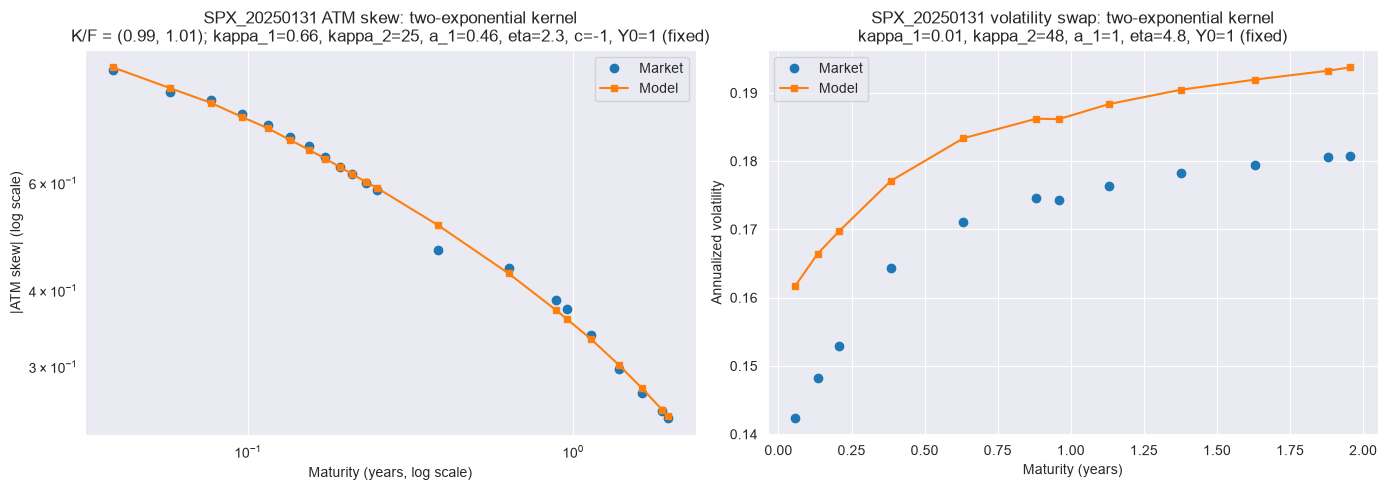

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2,Absolute RMSE,Relative RMSE (%)
0,SPX_20250131,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.025965,0.094702,0.657433,24.886429,0.455708,2.346555,-0.999,0.544292,NaN,NaN
1,SPX_20250131,Volatility swap,"kappa_1, kappa_2, a_1, eta",Y0 = 1,NaN,NaN,0.010000,47.710613,0.999999,4.789354,NaN,0.000001,0.014001,8.658542


In [157]:
dataset = 'SPX_20250131'
plot_kernel_calibration(dataset, 'two-exponential kernel', 'two_exp',
                        two_exp_atm_skew_results, two_exp_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [138]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250131'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5., 50.00, 1.00, 10, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250131 two-exponential ATM-skew parameters: [ 1.32106127 32.38807409  0.49687819  1.43712293 -0.99349979]
SX5E_20250131 two-exponential ATM-skew log RMSE: 3.564e-02


###### Calibration plots

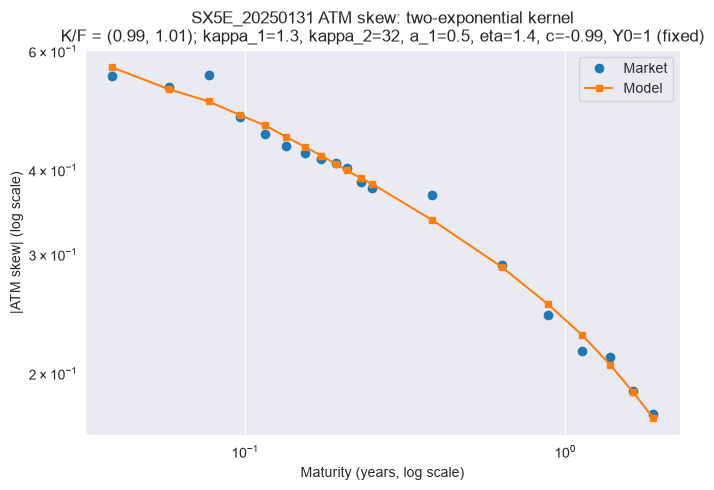

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SX5E_20250131,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.035639,0.089694,1.321061,32.388074,0.496878,1.437123,-0.9935,0.503122


In [139]:
dataset = 'SX5E_20250131'
plot_kernel_calibration(dataset, 'two-exponential kernel', 'two_exp',
                        two_exp_atm_skew_results, two_exp_vol_swap_results)


#### 2025-07-31

##### SPX

###### ATM skew calibration

In [162]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SPX_20250731'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5.0, 50.00, 1.00, 10., -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()


def two_exp_atm_skew_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SPX_20250731 two-exponential ATM-skew parameters: [ 0.45406779 19.96145495  0.3760569   2.93690044 -0.99899974]
SPX_20250731 two-exponential ATM-skew log RMSE: 2.732e-02


###### Volatility-swap calibration

The volatility-swap fit uses this date’s SPX quotes. Its initial parameters are taken from this date’s ATM-skew fit; edit them and the bounds below independently of the other date.

In [163]:
# Initialize from the parameters shared with the SPX ATM-skew calibration.
asset = 'SPX_20250731'
data = volatility_swap_data[asset]
maturities = data['maturity'].to_numpy(dtype=float)
market_quotes = market_volatility_swap_quotes[asset].copy()
atm_parameters = two_exp_atm_skew_results[asset]['parameters']
initial_parameters = atm_parameters[[0, 1, 2, 3]].copy()
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01], dtype=float)
upper_bounds = np.array([5.0, 50.00, 1.00, 10.], dtype=float)


def two_exp_vol_swap_spx_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_vol_swap(asset, T, parameters)
        for T in maturities
    ])
    return model - market_quotes


optimizer_result = least_squares(
    two_exp_vol_swap_spx_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_vol_swap(asset, T, calibrated_parameters)
    for T in maturities
])
errors = model - market_quotes
relative_errors = errors / market_quotes

two_exp_vol_swap_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_quotes': market_quotes,
    'model_quotes': model,
    'errors': errors,
    'RMSE': np.sqrt(np.mean(errors**2)),
    'relative_RMSE': np.sqrt(np.mean(relative_errors**2)),
    'maximum_error': np.max(np.abs(errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential volatility-swap parameters: {calibrated_parameters}')
print(f'{asset} two-exponential volatility-swap RMSE: {two_exp_vol_swap_results[asset]["RMSE"]:.3e}')


SPX_20250731 two-exponential volatility-swap parameters: [1.00000000e-02 4.73085078e+01 9.99996286e-01 4.39017990e+00]
SPX_20250731 two-exponential volatility-swap RMSE: 1.342e-02


###### Calibration plots

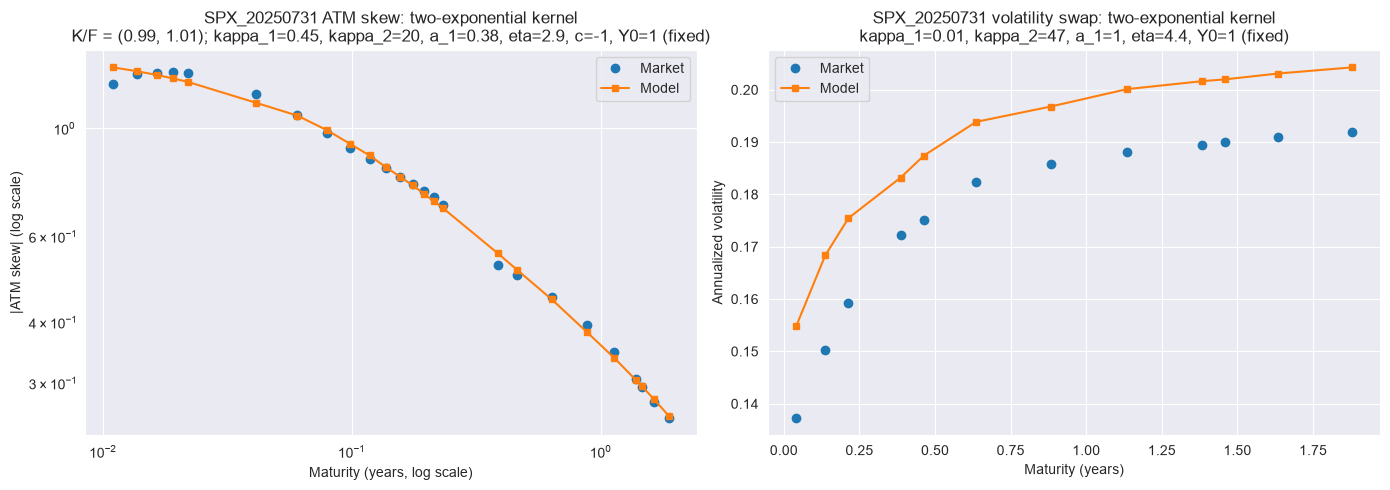

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2,Absolute RMSE,Relative RMSE (%)
0,SPX_20250731,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.027317,0.078641,0.454068,19.961455,0.376057,2.93690,-0.999,0.623943,NaN,NaN
1,SPX_20250731,Volatility swap,"kappa_1, kappa_2, a_1, eta",Y0 = 1,NaN,NaN,0.010000,47.308508,0.999996,4.39018,NaN,0.000004,0.01342,8.070862


In [164]:
dataset = 'SPX_20250731'
plot_kernel_calibration(dataset, 'two-exponential kernel', 'two_exp',
                        two_exp_atm_skew_results, two_exp_vol_swap_results)


##### SX5E

###### ATM skew calibration

In [146]:
# Parameters and bounds remain local so this calibration can be edited independently.
asset = 'SX5E_20250731'
initial_parameters = np.array([0.3, 5.0, 0.5, 0.3, -0.80], dtype=float)
lower_bounds = np.array([0.01, 3.0, 0.00, 0.01, -0.999], dtype=float)
upper_bounds = np.array([5, 50, 1.00, 10, -0.001], dtype=float)
maturities = market_skew_maturities[asset].copy()
market_quotes = market_skews[asset].copy()

def two_exp_atm_skew_sx5e_residuals(
    parameters,
    *,
    asset=asset,
    maturities=maturities.copy(),
    market_quotes=market_quotes.copy(),
):
    model = np.array([
        two_exp_atm_skew(asset, T, parameters)
        for T in maturities
    ])
    return log_absolute_skew_residuals(model, market_quotes)


optimizer_result = least_squares(
    two_exp_atm_skew_sx5e_residuals,
    x0=initial_parameters,
    bounds=(lower_bounds, upper_bounds),
    method='trf',
    x_scale='jac',
)

calibrated_parameters = optimizer_result.x.copy()
model = np.array([
    two_exp_atm_skew(asset, T, calibrated_parameters)
    for T in maturities
])
log_errors = log_absolute_skew_residuals(model, market_quotes)

two_exp_atm_skew_results[asset] = {
    'parameter_names': ['kappa_1', 'kappa_2', 'a_1', 'eta', 'c'],
    'parameters': calibrated_parameters,
    'fixed_parameters': {'Y0': Y0_VALUE},
    'maturities': maturities,
    'market_skews': market_quotes,
    'model_skews': model,
    'log_errors': log_errors,
    'log_RMSE': np.sqrt(np.mean(log_errors**2)),
    'maximum_log_error': np.max(np.abs(log_errors)),
    'optimizer_result': optimizer_result,
}

print(f'{asset} two-exponential ATM-skew parameters: {calibrated_parameters}')
print(f'{asset} two-exponential ATM-skew log RMSE: {two_exp_atm_skew_results[asset]["log_RMSE"]:.3e}')


SX5E_20250731 two-exponential ATM-skew parameters: [ 0.07793725 20.27214231  0.26363064  3.10673805 -0.74868058]
SX5E_20250731 two-exponential ATM-skew log RMSE: 1.978e-02


###### Calibration plots

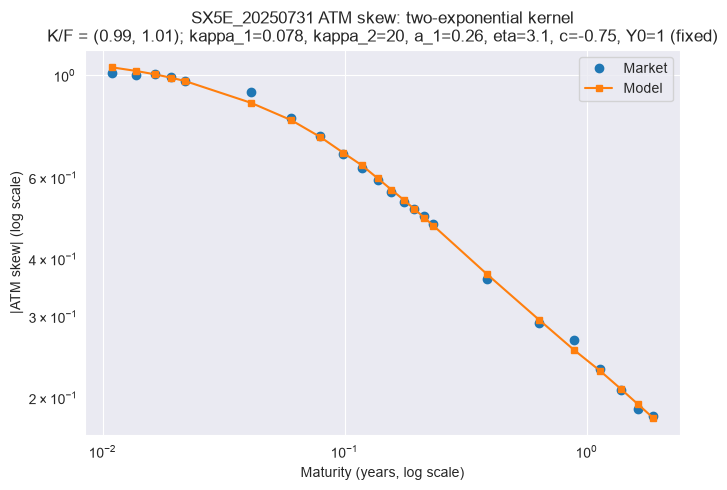

,Dataset,Calibration,Calibrated parameters,Fixed parameters,Log-skew RMSE,Maximum log-skew error,kappa_1,kappa_2,a_1,eta,c,a_2
0,SX5E_20250731,ATM skew,"kappa_1, kappa_2, a_1, eta, c",Y0 = 1,0.019783,0.055599,0.077937,20.272142,0.263631,3.106738,-0.748681,0.736369


In [147]:
dataset = 'SX5E_20250731'
plot_kernel_calibration(dataset, 'two-exponential kernel', 'two_exp',
                        two_exp_atm_skew_results, two_exp_vol_swap_results)


## Cross-kernel calibration results

This section compares the four calibrated kernels separately for the January
and July snapshots. Each date's figure contains SPX and SX5E ATM-skew
comparisons and the SPX volatility-swap comparison. The SX5E volatility-swap
panel is intentionally absent because CACIB provided no such quotes.

In [168]:
kernel_results = [
    ('Fractional', atm_skew_results, vol_swap_results, 'tab:blue'),
    ('Shifted fractional', shifted_fractional_atm_skew_results,
     shifted_fractional_vol_swap_results, 'tab:orange'),
    ('One exponential', one_exp_atm_skew_results, one_exp_vol_swap_results,
     'tab:green'),
    ('Two exponentials', two_exp_atm_skew_results, two_exp_vol_swap_results,
     'tab:red'),
]
cross_kernel_calibration_summary_by_date = {}


### 2025-01-31

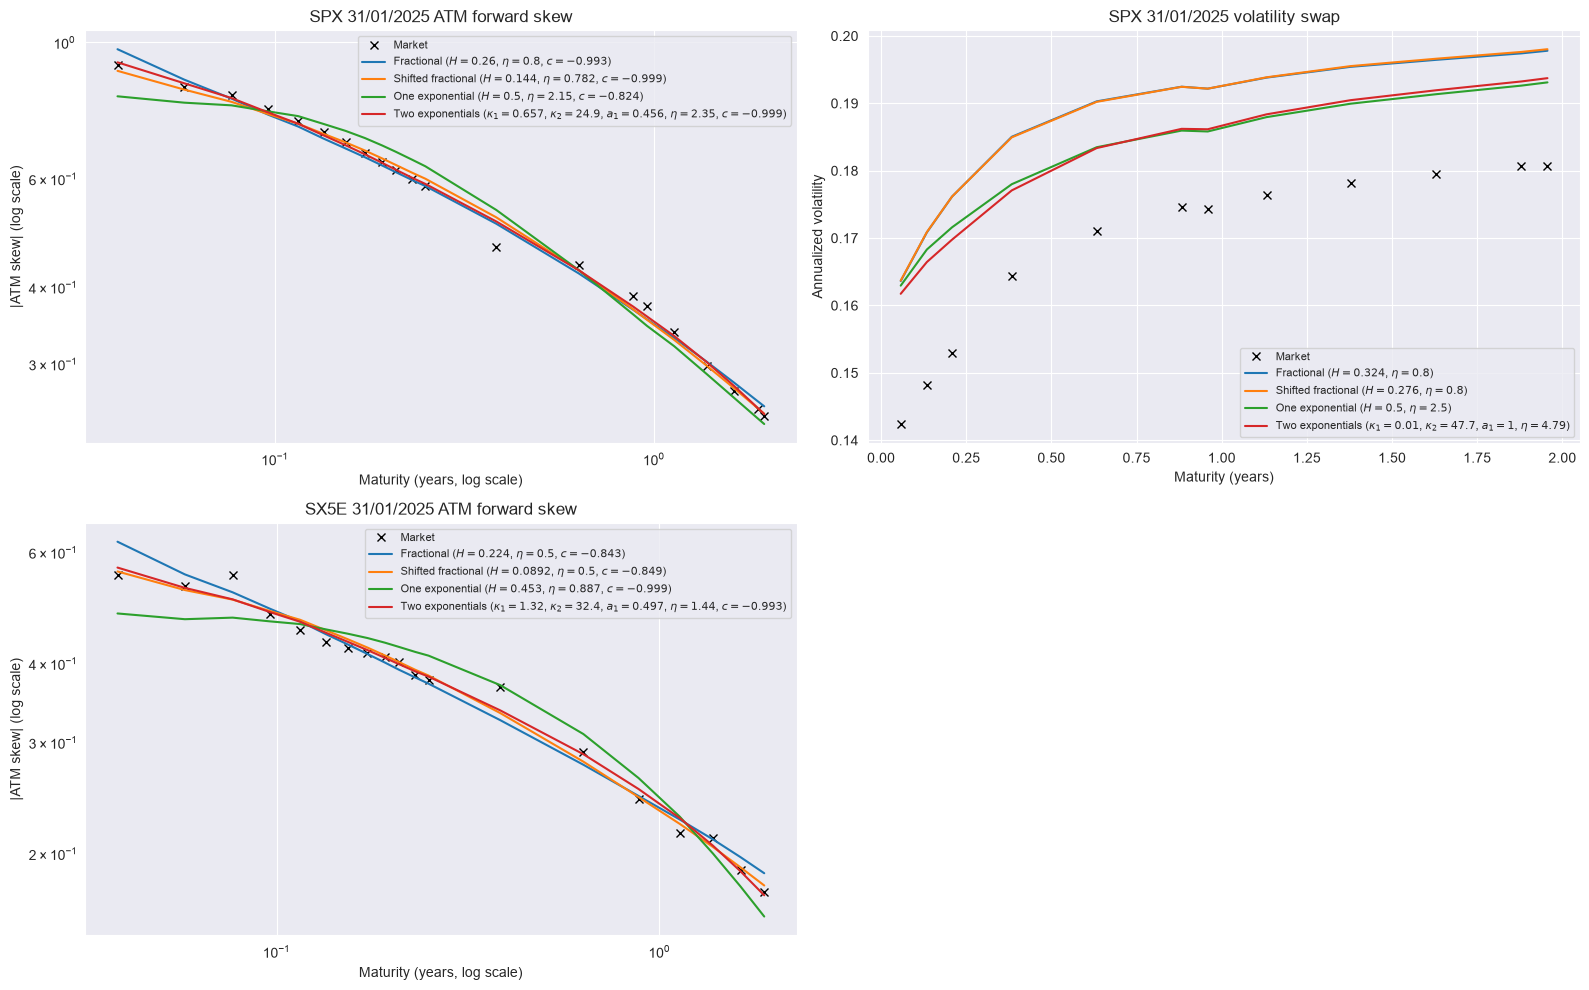

In [181]:
missing = []
for label, skew_results, vol_results, _ in kernel_results:
    for dataset in ('SPX_20250131', 'SX5E_20250131'):
        if dataset not in skew_results:
            missing.append(f'{label} / {dataset} / ATM skew')
        if dataset.startswith('SPX') and dataset not in vol_results:
            missing.append(f'{label} / {dataset} / volatility swap')
if missing:
    raise RuntimeError(f'Run all four kernel sections for 20250131 first; missing: {missing}')


date = '20250131'  # Mettre '20250731' dans la section de juillet
date_label = f'{date[6:8]}/{date[4:6]}/{date[:4]}'

PARAMETER_TEX = {
    'H': r'H',
    'eta': r'\eta',
    'c': r'c',
    'kappa_1': r'\kappa_1',
    'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}


def label_with_parameters(kernel_label, result):
    parameters = ', '.join(
        f'${PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(
            result['parameter_names'],
            result['parameters'],
        )
    )
    return f'{kernel_label} ({parameters})'


fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'

    # ATM forward skew
    skew_ax = axes[row, 0]
    market_atm = kernel_results[0][1][dataset]

    skew_ax.loglog(
        market_atm['maturities'],
        np.abs(market_atm['market_skews']),
        'x', color='black', label='Market',
    )

    for kernel_label, skew_results, vol_results, color in kernel_results:
        result = skew_results[dataset]
        skew_ax.loglog(
            result['maturities'],
            np.abs(result['model_skews']),
            '-', color=color,
            label=label_with_parameters(kernel_label, result),
        )

    skew_ax.set_title(f'{asset_label} {date_label} ATM forward skew')
    skew_ax.set_xlabel('Maturity (years, log scale)')
    skew_ax.set_ylabel('|ATM skew| (log scale)')
    skew_ax.grid(True)
    skew_ax.legend(fontsize=8)

    # Volatility swap : données disponibles uniquement pour SPX
    vol_ax = axes[row, 1]

    if asset_label == 'SPX':
        market_vol = kernel_results[0][2][dataset]

        vol_ax.plot(
            market_vol['maturities'],
            market_vol['market_quotes'],
            'x', color='black', label='Market',
        )

        for kernel_label, skew_results, vol_results, color in kernel_results:
            result = vol_results[dataset]
            vol_ax.plot(
                result['maturities'],
                result['model_quotes'],
                '-', color=color,
                label=label_with_parameters(kernel_label, result),
            )

        vol_ax.set_title(f'{asset_label} {date_label} volatility swap')
        vol_ax.set_xlabel('Maturity (years)')
        vol_ax.set_ylabel('Annualized volatility')
        vol_ax.grid(True)
        vol_ax.legend(fontsize=8)
    else:
        vol_ax.axis('off')

fig.tight_layout()

target = ATM_SKEW_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(
    target / 'cross_kernel_calibration_results.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()


### 2025-07-31

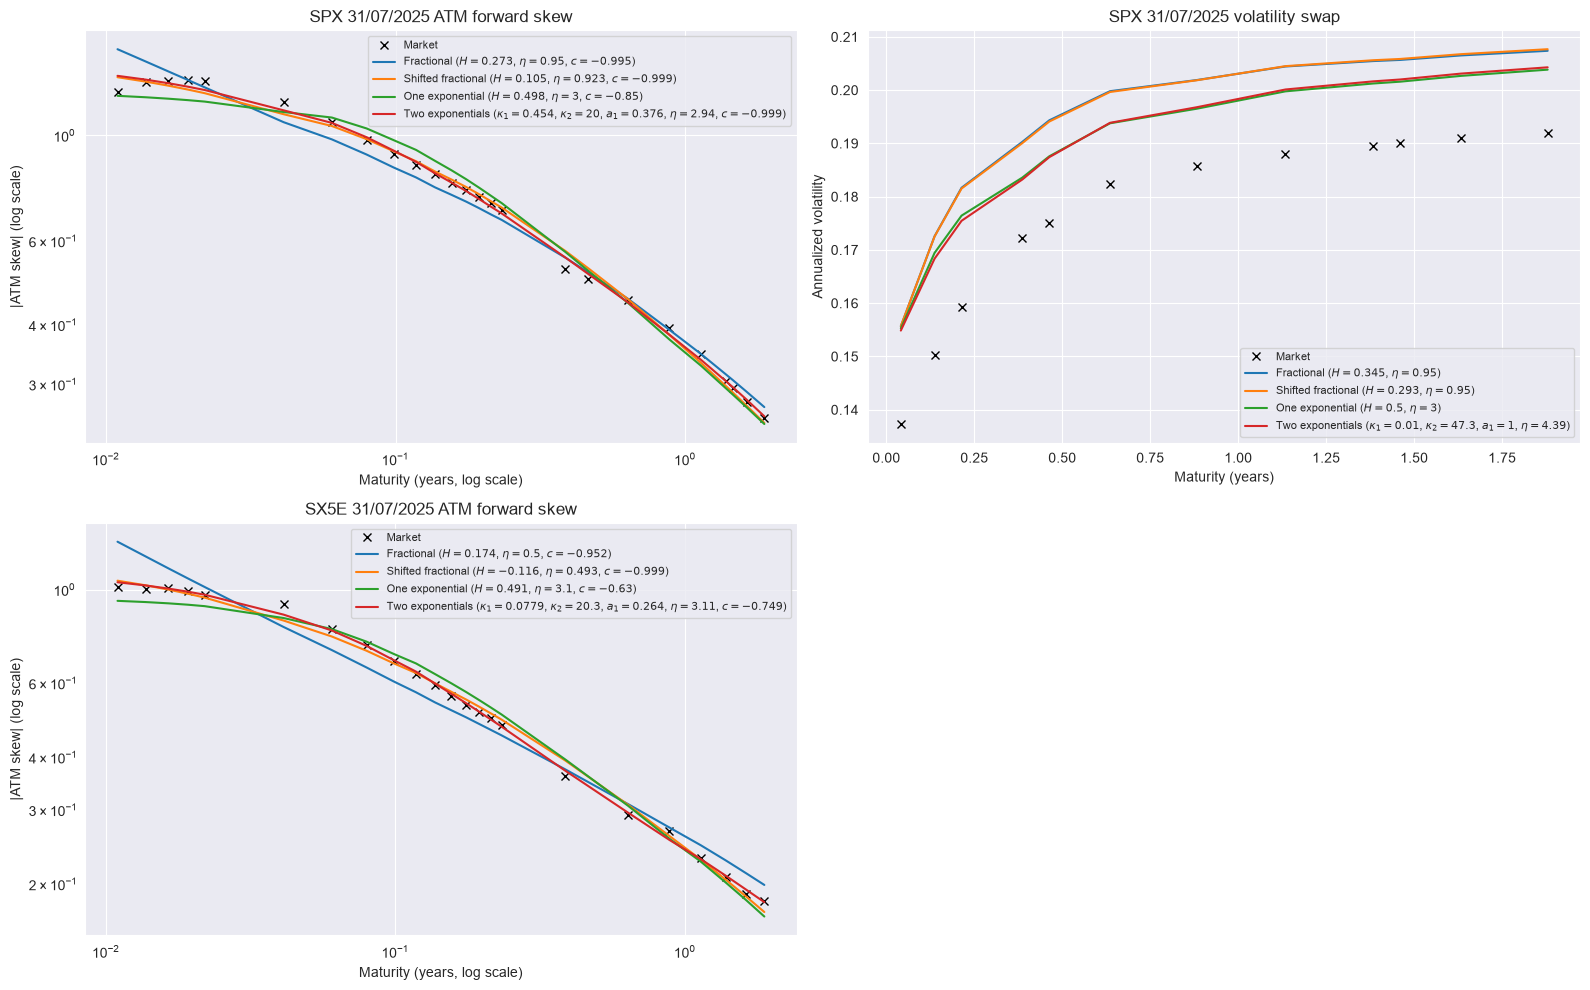

In [183]:
missing = []
for label, skew_results, vol_results, _ in kernel_results:
    for dataset in ('SPX_20250731', 'SX5E_20250731'):
        if dataset not in skew_results:
            missing.append(f'{label} / {dataset} / ATM skew')
        if dataset.startswith('SPX') and dataset not in vol_results:
            missing.append(f'{label} / {dataset} / volatility swap')

if missing:
    raise RuntimeError(
        f'Run all four kernel sections for 20250731 first; missing: {missing}'
    )


PARAMETER_TEX = {
    'H': r'H',
    'eta': r'\eta',
    'c': r'c',
    'kappa_1': r'\kappa_1',
    'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}


def label_with_parameters(kernel_label, result):
    parameters = ', '.join(
        f'${PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(
            result['parameter_names'],
            result['parameters'],
        )
    )
    return f'{kernel_label} ({parameters})'


date = '20250731'
date_label = f'{date[6:8]}/{date[4:6]}/{date[:4]}'

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row, asset_label in enumerate(('SPX', 'SX5E')):
    dataset = f'{asset_label}_{date}'

    # ATM forward skew
    skew_ax = axes[row, 0]
    market_atm = kernel_results[0][1][dataset]

    skew_ax.loglog(
        market_atm['maturities'],
        np.abs(market_atm['market_skews']),
        'x', color='black', label='Market',
    )

    for kernel_label, skew_results, vol_results, color in kernel_results:
        result = skew_results[dataset]
        skew_ax.loglog(
            result['maturities'],
            np.abs(result['model_skews']),
            '-', color=color,
            label=label_with_parameters(kernel_label, result),
        )

    skew_ax.set_title(f'{asset_label} {date_label} ATM forward skew')
    skew_ax.set_xlabel('Maturity (years, log scale)')
    skew_ax.set_ylabel('|ATM skew| (log scale)')
    skew_ax.grid(True)
    skew_ax.legend(fontsize=8)

    # Volatility swap: available for SPX only
    vol_ax = axes[row, 1]

    if asset_label == 'SPX':
        market_vol = kernel_results[0][2][dataset]

        vol_ax.plot(
            market_vol['maturities'],
            market_vol['market_quotes'],
            'x', color='black', label='Market',
        )

        for kernel_label, skew_results, vol_results, color in kernel_results:
            result = vol_results[dataset]
            vol_ax.plot(
                result['maturities'],
                result['model_quotes'],
                '-', color=color,
                label=label_with_parameters(kernel_label, result),
            )

        vol_ax.set_title(f'{asset_label} {date_label} volatility swap')
        vol_ax.set_xlabel('Maturity (years)')
        vol_ax.set_ylabel('Annualized volatility')
        vol_ax.grid(True)
        vol_ax.legend(fontsize=8)
    else:
        vol_ax.axis('off')

fig.tight_layout()

target = ATM_SKEW_PLOTS_DIRECTORY / date
target.mkdir(parents=True, exist_ok=True)
fig.savefig(
    target / 'cross_kernel_calibration_results.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()